<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-053-fock-state-cavity.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 053 <br>
<hr/>

# Lab 053 — Fock state in a leaky cavity

We want a cavity that holds exactly one photon. The cavity loses its photons through the mirrors, the only control is a classical beam that drives it, and the only information is the noisy reading of a photon-number meter. A constant drive cannot do the job well, because a classically driven cavity holds light with Poisson photon statistics, and one photon with certainty is a state that classical light never produces. A drive that reacts to the meter readings does much better. We let a neural network learn such a feedback rule from rewards alone, with the policy-gradient method.

This notebook reimplements, in simplified form, the cavity feedback example of F. Marquardt, *Machine learning and quantum devices*, SciPost Phys. Lect. Notes **29** (2021), [doi:10.21468/SciPostPhysLectNotes.29](https://doi.org/10.21468/SciPostPhysLectNotes.29), Section 3.1.5 ([arXiv:2101.01759](https://arxiv.org/abs/2101.01759)). The task, the model of a driven, decaying and weakly measured cavity mode, and the use of policy gradients on measurement traces are his. We first build the physics from the beginning, the cavity mode as a harmonic oscillator, the photon-number states, the coherent state produced by a drive, photon loss and the meter. We then compute the best result of a constant drive, train the feedback agent, and compare the two. We close with a list of what differs from the original setup.

The whole notebook is written in JAX. The quantum simulation applies the operators directly to the state vector, in the matrix-free style and with the conventions of the SmoQ.jax engine ([github.com/MarcinPlodzien/SmoQ.jax](https://github.com/MarcinPlodzien/SmoQ.jax)). The few primitives taken from this engine are copied into one cell at the top, and the trajectory rule for a channel is adapted from it. Time loops run as `jax.lax.scan`, the trajectories of a batch run in parallel with `jax.vmap`, and the policy network is trained with `jax.grad` and the Adam optimiser of Optax.

## Student route and independent diagnostics
Follow the cavity mode, drive, loss and meter derivations before the control task and policy-gradient cells. The main route ends after the independently evaluated learned controller, constant-drive reference and threshold rule. The full recorded training remains available.

The baseline in this recorded study includes each trajectory in its own batch mean. For independent batches of size B, the unnormalised estimator has expectation (1-1/B) times the true gradient. The text below states the small bias. [Lab 058](lab-058-finite-budget-ghz.ipynb) derives and tests a leave-one-out alternative. [Lab 060](lab-060-cavity-checks.ipynb) supplies a separate short experiment with timestep, cutoff, noise and window checks. It trains no new controller.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*.
> 2. `jax`, `optax`, `numpy`, `scipy` and `matplotlib` are pre-installed in Colab. The first code cell sets `JAX_PLATFORMS=cpu`. No data files are needed.
> 3. Run the cells in order. Later cells use variables defined earlier. The last cell prints the run time of the whole notebook, recorded on a multi-core CPU that was shared with other jobs.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)
import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyBboxPatch
from scipy.stats import norm

import jax, jax.numpy as jnp
from jax import lax
jax.config.update("jax_enable_x64", True)   # quantum states in complex128, as in SmoQ.jax
import optax

t_start = time.time()
CDTYPE, RDTYPE = jnp.complex128, jnp.float64

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, UJSky, DSOrange, UJGray = "#005CA7", "#002B5C", "#6CACE4", "#D35A05", "#5A6270"
C_AGENT, C_CONST, C_NONE = UJBlue, DSOrange, UJGray

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

NUMBERS = {}

The next cell holds the four functions taken over from SmoQ.jax, with their names and docstrings unchanged. `normalize` divides a state by its length, so that the probabilities $|\psi_n|^2$ add up to one. `_sqrtm_psd` and `_expm_herm` compute the square root of a positive matrix and the propagator $e^{-i\tau h}$ of a small Hermitian matrix $h$ from its eigenvalues and eigenvectors, which is how we build the evolution over one time step. `kraus_from_jump` builds the two operators $\hat K_0$ and $\hat K_1$ that describe one short time step of an open quantum system. $\hat K_1$ describes a quantum jump, for us the escape of a photon, and $\hat K_0$ the evolution when no jump happens. They satisfy $\hat K_0^\dagger\hat K_0+\hat K_1^\dagger\hat K_1=1$, so the probabilities of the two outcomes add up to one. Their meaning becomes concrete in Section 3, where we use them for photon loss.

In [2]:
# ---- primitives copied from SmoQ.jax (https://github.com/MarcinPlodzien/SmoQ.jax), engine.py ----
def normalize(psi):
    """psi / ||psi||  (Frobenius norm of the tensor = 2-norm of the state vector)."""
    return psi / jnp.linalg.norm(psi)


def _sqrtm_psd(A):
    """Square root of a positive semi-definite matrix via eigendecomposition: V sqrt(w) V^dag."""
    w, v = jnp.linalg.eigh(A)
    return (v * jnp.sqrt(jnp.clip(w, 0, None))) @ v.conj().T


def _expm_herm(h, tau):
    """exp(-i tau h) for a SMALL Hermitian matrix: h = V w V^dag  =>  V exp(-i tau w) V^dag."""
    w, v = jnp.linalg.eigh(jnp.asarray(h, dtype=CDTYPE))
    return (v * jnp.exp(-1j * tau * w)) @ v.conj().T


def kraus_from_jump(L, gamma_dt):
    """Kraus pair generated by a Lindblad jump operator L acting for a short time dt (rate gamma):
        K1 = sqrt(gamma dt) L                      'a jump happened'
        K0 = sqrt(1 - gamma dt L^dag L)            'no jump'  (~ exp(-gamma dt L^dag L / 2))
    Completeness K0^dag K0 + K1^dag K1 = 1 holds EXACTLY whenever gamma dt ||L^dag L|| <= 1, so that
    1 - gamma dt L^dag L is positive semidefinite and its square root exists; the map is then trace preserving.
    For larger steps the negative eigenvalues are clipped by _sqrtm_psd and completeness FAILS (decay L = |0><1| = SP,
    gamma dt = 1.5: error 0.5).  It reproduces the Lindblad dissipator up to O(dt^2)."""
    L = jnp.asarray(L, dtype=CDTYPE)
    K0 = _sqrtm_psd(jnp.eye(L.shape[0], dtype=CDTYPE) - gamma_dt * (L.conj().T @ L))
    return jnp.stack([K0, jnp.sqrt(gamma_dt) * L])

<hr/>
## 1. One mode of light in a cavity

Two mirrors facing each other trap light of the frequencies whose standing waves fit between them. We keep one of these standing waves, one mode of frequency $\omega_c$. The electric field of the mode oscillates like the position of a mass on a spring, and in quantum mechanics the mode is a harmonic oscillator,
$$\hat{\mathcal H}_{\rm c}=\hbar\omega_c\Big(\hat a^\dagger\hat a+\tfrac12\Big).$$
Its energy levels are equally spaced, $E_n=\hbar\omega_c(n+\tfrac12)$ with $n=0,1,2,\dots$. The eigenstate $|n\rangle$ holds $n$ quanta of energy $\hbar\omega_c$, and a quantum of a light mode is a photon. The states $|n\rangle$ are therefore the states with exactly $n$ photons, called Fock states, and $|0\rangle$ is the empty cavity, the vacuum.

The annihilation operator $\hat a$ removes one photon and the creation operator $\hat a^\dagger$ adds one,
$$\hat a\,|n\rangle=\sqrt n\,|n-1\rangle,\qquad \hat a^\dagger|n\rangle=\sqrt{n+1}\,|n+1\rangle,\qquad \hat n=\hat a^\dagger\hat a,\quad \hat n|n\rangle=n|n\rangle .$$
On a computer we keep the levels $n=0,\dots,N-1$ and write the operators as matrices in this basis. The matrix of $\hat a$ has the numbers $\sqrt1,\sqrt2,\dots$ just above the diagonal. The cut at $N$ levels changes the commutator $[\hat a,\hat a^\dagger]=1$ in the last entry only, so it is harmless as long as the highest levels stay empty, which we check for the trained agent.

A state of the mode is stored as the vector of its amplitudes $\psi_n=\langle n|\psi\rangle$, $n=0,\dots,N-1$. The cell below applies $\hat a$ and $\hat a^\dagger$ directly to this vector, by shifting every amplitude one level down or up and multiplying it by $\sqrt n$. For a check we also build the matrices from this action, column $j$ being the image of the basis state $|j\rangle$, and print them for $N=4$.

In [3]:
# Fock space with the levels n = 0..N-1; a state is a vector psi[n] (a rank-1 tensor, one axis for the mode)
def fock_tools(N):
    nvec = jnp.arange(N, dtype=RDTYPE)
    sqn = jnp.sqrt(nvec)
    def apply_a(psi):        # (a psi)_n = sqrt(n+1) psi_{n+1}: every amplitude moves one level down
        return jnp.concatenate([psi[1:] * sqn[1:], jnp.zeros(1, psi.dtype)])
    def apply_ad(psi):       # (a^dag psi)_n = sqrt(n) psi_{n-1}: every amplitude moves one level up
        return jnp.concatenate([jnp.zeros(1, psi.dtype), psi[:-1] * sqn[1:]])
    return nvec, apply_a, apply_ad

def apply_kraus_mcwf_mode(key, psi, kraus):
    """Channel on a PURE state of one mode, stochastically (quantum trajectory), in the form of apply_kraus_mcwf:
    branch m with probability p_m = ||K_m psi||^2, then |psi> -> K_m|psi> / sqrt(p_m).
    Averaging |psi><psi| over trajectories gives sum_m K_m rho K_m^dag. Returns the new state and m."""
    phis = jnp.einsum("mab,b->ma", kraus, psi)
    probs = jnp.sum(jnp.abs(phis)**2, axis=1)
    m = jax.random.categorical(key, jnp.log(jnp.clip(probs, 1e-300, None)))
    return normalize(phis[m]), m

def apply_kraus_dm_mode(rho, kraus):
    """rho -> sum_m K_m rho K_m^dag for the density matrix of one mode."""
    return jnp.einsum("mab,bc,mdc->ad", kraus, rho, kraus.conj())

def dense(op, N):
    # dense matrix for VALIDATION on small N, built from the matrix-free action: column j is op|e_j>
    return jax.vmap(op)(jnp.eye(N, dtype=CDTYPE)).T

_, a_4, ad_4 = fock_tools(4)
A4, AD4 = np.real(np.asarray(dense(a_4, 4))), np.real(np.asarray(dense(ad_4, 4)))
np.set_printoptions(precision=3, suppress=True)
print("annihilation operator a (4 levels):\n", A4)
print("creation operator a^dagger:\n", AD4)
print("number operator a^dagger a:\n", AD4 @ A4)
print("commutator [a, a^dagger] (the last entry is the truncation):\n", A4 @ AD4 - AD4 @ A4)

annihilation operator a (4 levels):
 [[0.    1.    0.    0.   ]
 [0.    0.    1.414 0.   ]
 [0.    0.    0.    1.732]
 [0.    0.    0.    0.   ]]
creation operator a^dagger:
 [[0.    0.    0.    0.   ]
 [1.    0.    0.    0.   ]
 [0.    1.414 0.    0.   ]
 [0.    0.    1.732 0.   ]]
number operator a^dagger a:
 [[0. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 2. 0.]
 [0. 0. 0. 3.]]
commutator [a, a^dagger] (the last entry is the truncation):
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -3.]]


The printout can be checked against the formulas. The second column of $\hat a$ is $(1,0,0,0)$, which is $\hat a|1\rangle=|0\rangle$, and the third column has $\sqrt2\approx1.414$ in the second row, which is $\hat a|2\rangle=\sqrt2\,|1\rangle$. The product $\hat a^\dagger\hat a$ is diagonal with the entries $0,1,2,3$, the photon numbers of the four levels. The commutator equals one on the diagonal except in the last entry, $1-N=-3$, where the missing level $|N\rangle$ would be needed.

The figure shows the ladder of Fock states. The arrows mark what the two operators do, with the factor that multiplies the new state. These factors grow with $n$, so the amplitude for adding a photon is larger in a cavity that already holds photons, the bosonic enhancement behind stimulated emission.

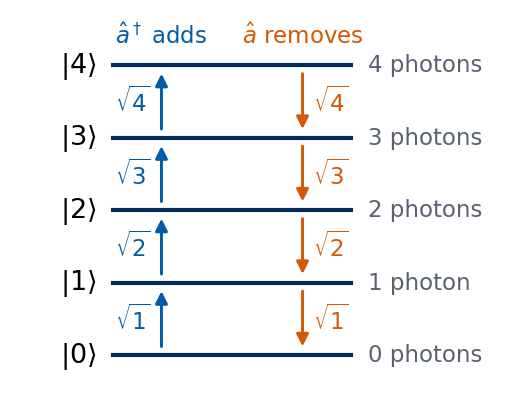

In [4]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.2, 3.2))
    for n_ in range(5):
        ax.plot([0, 2.2], [n_, n_], color=UJNavy, lw=2)
        ax.text(-0.15, n_, rf"$|{n_}\rangle$", ha="right", va="center", fontsize=13)
        ax.text(2.35, n_, f"{n_} photon" + ("s" if n_ != 1 else ""), ha="left", va="center", fontsize=11, color=UJGray)
    for n_ in range(4):
        ax.add_patch(FancyArrowPatch((0.45, n_ + 0.06), (0.45, n_ + 0.94), arrowstyle="-|>", mutation_scale=12, color=UJBlue, lw=1.4))
        ax.text(0.35, n_ + 0.5, rf"$\sqrt{{{n_+1}}}$", ha="right", va="center", fontsize=11, color=UJBlue)
        ax.add_patch(FancyArrowPatch((1.75, n_ + 0.94), (1.75, n_ + 0.06), arrowstyle="-|>", mutation_scale=12, color=DSOrange, lw=1.4))
        ax.text(1.85, n_ + 0.5, rf"$\sqrt{{{n_+1}}}$", ha="left", va="center", fontsize=11, color=DSOrange)
    ax.text(0.45, 4.3, r"$\hat a^\dagger$ adds", ha="center", fontsize=11, color=UJBlue)
    ax.text(1.75, 4.3, r"$\hat a$ removes", ha="center", fontsize=11, color=DSOrange)
    ax.set_xlim(-0.9, 3.6); ax.set_ylim(-0.4, 4.7); ax.axis("off")
    save(fig, "fig_lab053_ladder"); plt.show()

<hr/>
## 2. A classical drive makes a coherent state

A laser or microwave beam sent onto the cavity at the mode frequency drives the mode. Every amplitude $\psi_n$ of the undriven mode turns in the complex plane as $e^{-in\omega_c t}$. We describe the state in a frame that turns along with this motion, the rotating frame. In this frame the term $\hbar\omega_c\hat n$ drops out of the Hamiltonian and only the drive is left. We follow the source and write the drive Hamiltonian in units with $\hbar=1$ as
$$\hat{\mathcal H}_{\rm d}=i\,\varepsilon\,(\hat a^\dagger-\hat a),$$
with a real drive strength $\varepsilon$. In the notation of the source $\varepsilon=\sqrt\kappa\,\alpha_{\rm in}$, where $|\alpha_{\rm in}|^2$ is the number of drive photons per unit time that hit the cavity and $\kappa$ is the loss rate introduced below. Starting from the vacuum, the drive acting for a time $t$ produces the state $e^{\varepsilon t(\hat a^\dagger-\hat a)}|0\rangle=|\alpha\rangle$ with $\alpha=\varepsilon t$. This is the coherent state, the state of the field of a classical oscillating current or of a laser. In the Fock basis
$$|\alpha\rangle=e^{-|\alpha|^2/2}\sum_{n\ge0}\frac{\alpha^n}{\sqrt{n!}}\,|n\rangle,\qquad P(n)=|\langle n|\alpha\rangle|^2=e^{-|\alpha|^2}\,\frac{|\alpha|^{2n}}{n!}.$$
The photon number is Poisson distributed with mean $\bar n=|\alpha|^2$ and variance $\bar n$. The cell checks the formula for $\varepsilon=1$ and $t=1$, where $\alpha=1$, by applying the propagator $e^{-i\hat{\mathcal H}_{\rm d}t}$ to the vacuum numerically and comparing the populations with the Poisson values.

In [5]:
N = 12                       # Fock levels 0..11 kept in all simulations
NVEC, apply_a, apply_ad = fock_tools(N)
nvec = np.asarray(NVEC)
VAC = jnp.zeros(N, CDTYPE).at[0].set(1.0)

# the drive Hamiltonian H_d = i eps (a^dag - a) for eps = 1, as a small N x N matrix of the single mode
HD1 = dense(lambda p: 1j * (apply_ad(p) - apply_a(p)), N)

def poisson(nbar, nmax):
    from math import factorial
    return np.array([np.exp(-nbar) * nbar**k / factorial(k) for k in range(nmax)])

eps_test, t_test = 1.0, 1.0
psi = _expm_herm(eps_test * HD1, t_test) @ VAC          # drive acting on |0> for the time t
print("P(n) from the simulated drive:", np.round(np.abs(np.asarray(psi[:6]))**2, 4))
print("Poisson with |alpha|^2 = 1   :", np.round(poisson((eps_test * t_test)**2, 6), 4))

P(n) from the simulated drive: [0.368 0.368 0.184 0.061 0.015 0.003]
Poisson with |alpha|^2 = 1   : [0.368 0.368 0.184 0.061 0.015 0.003]


The two rows agree in every printed digit, so the simulated drive produces the coherent state with $\alpha=\varepsilon t$. The probability of one photon in a coherent state is $P(1)=\bar n\,e^{-\bar n}$. It vanishes for an empty cavity and for a bright one, and its largest value is reached at $\bar n=1$,
$$\max_{\bar n}\ \bar n\,e^{-\bar n}=e^{-1}\approx0.368 .$$
For a drive that is not perfectly controlled the cavity holds a mixture of coherent states with different $\alpha$, and $P(1)$ of a mixture is the average of the values of its members, so it never exceeds $e^{-1}$ either. The figure shows the Poisson distribution for three mean photon numbers, together with the distribution of $|1\rangle$, which is the single bar $P(1)=1$ (dashed outline). The dotted line marks $e^{-1}$.

max of nbar*exp(-nbar) on a grid: 0.3679 at nbar = 1.000
exp(-1) = 0.3679


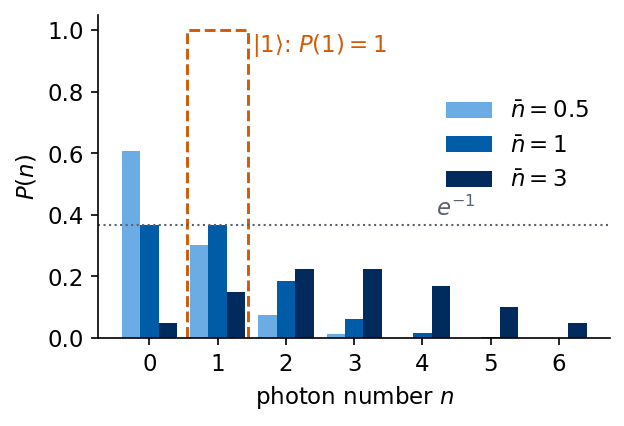

In [6]:
P1_coh_max = float(np.exp(-1.0))
nbar_grid = np.linspace(0, 5, 2001)
print(f"max of nbar*exp(-nbar) on a grid: {np.max(nbar_grid*np.exp(-nbar_grid)):.4f} at nbar = {nbar_grid[np.argmax(nbar_grid*np.exp(-nbar_grid))]:.3f}")
print(f"exp(-1) = {P1_coh_max:.4f}")
NUMBERS["P1_coherent_max"] = P1_coh_max

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.8))
    ks = np.arange(7); w = 0.27
    for j, (nb_, c) in enumerate(((0.5, UJSky), (1.0, UJBlue), (3.0, UJNavy))):
        ax.bar(ks + (j - 1) * w, poisson(nb_, 7), width=w, color=c, label=rf"$\bar n={nb_:g}$")
    ax.bar([1], [1.0], width=0.9, fill=False, edgecolor=DSOrange, lw=1.4, ls="--")
    ax.text(1.5, 0.93, r"$|1\rangle$: $P(1)=1$", color=DSOrange, fontsize=11)
    ax.axhline(P1_coh_max, color=UJGray, lw=1, ls=":")
    ax.text(4.2, P1_coh_max + 0.03, r"$e^{-1}$", color=UJGray, fontsize=11)
    ax.set_xlabel("photon number $n$"); ax.set_ylabel(r"$P(n)$")
    ax.set_xticks(ks); ax.set_ylim(0, 1.05); ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.8))
    save(fig, "fig_lab053_poisson"); plt.show()

The Fock state $|1\rangle$ has $P(1)=1$ and a photon number without any spread, $\mathrm{Var}\,n=0$. The Mandel parameter $Q=\mathrm{Var}\,n/\bar n-1$ [L. Mandel, Opt. Lett. **4**, 205 (1979), [doi:10.1364/OL.4.000205](https://doi.org/10.1364/OL.4.000205)] measures the spread relative to the Poisson value. It is $Q=0$ for every coherent state and $Q\ge0$ for every mixture of coherent states, because the spread of $|\alpha|^2$ between the members adds to the Poisson spread. The one-photon state has $\bar n=1$ and $\mathrm{Var}\,n=0$, hence $Q=-1$. Light with $Q<0$ is called sub-Poissonian, and it is a nonclassical state of light. A linear drive together with photon loss keeps a coherent state coherent, as the next section shows, so these two alone cannot produce it. To go beyond $P(1)=e^{-1}$ we need an element that acts differently on different photon numbers. In this notebook that element is the photon-number meter together with feedback.

<hr/>
## 3. Photons leak out of the cavity

The mirrors are not perfect. Each photon leaves the cavity with the probability $\kappa\,dt$ in a short time $dt$, so a cavity with $n$ photons loses one with the probability $\kappa n\,dt$. The rate $\kappa$ sets the time unit of the notebook, and all times are given in units of $1/\kappa$.

The loss is random and we simulate it as such, one run of the cavity at a time. Such a run is called a quantum trajectory. In each short time step $\Delta t_{\rm s}$ the state is updated by one of two rules.
- with the probability $p_{\rm jump}=\kappa\Delta t_{\rm s}\,\langle\hat n\rangle$ a photon leaves, and the state jumps to $\hat a|\psi\rangle$, normalised,
- otherwise no photon leaves, and the state changes smoothly to $\sqrt{1-\kappa\Delta t_{\rm s}\,\hat n}\,|\psi\rangle$, normalised.

The two rules are the operators $\hat K_1=\sqrt{\kappa\Delta t_{\rm s}}\,\hat a$ and $\hat K_0=\sqrt{1-\kappa\Delta t_{\rm s}\,\hat n}$ that `kraus_from_jump` builds for the jump operator $\hat a$, and the probability of each rule is $\|\hat K_m|\psi\rangle\|^2$, which for $\hat K_1$ is $\kappa\Delta t_{\rm s}\langle\hat n\rangle$. The second rule reduces the weight of the states with many photons. A stretch of time without a leaked photon is evidence that the cavity holds few photons, and the state is updated accordingly. Averaging the two rules over many trajectories gives the density matrix $\hat\rho$, and its evolution with the drive is the Lindblad master equation
$$\frac{d\hat\rho}{dt}=-i[\hat{\mathcal H}_{\rm d},\hat\rho]+\kappa\Big(\hat a\hat\rho\hat a^\dagger-\tfrac12\hat a^\dagger\hat a\hat\rho-\tfrac12\hat\rho\hat a^\dagger\hat a\Big),$$
which our discrete rule reproduces to first order in $\Delta t_{\rm s}$ [H. M. Wiseman and G. J. Milburn, *Quantum Measurement and Control*, Cambridge University Press (2009), [doi:10.1017/CBO9780511813948](https://doi.org/10.1017/CBO9780511813948)]. We use $\Delta t_{\rm s}=0.01/\kappa$. The cell below builds the two operators, checks that their probabilities add up to one, and defines one loss step of a trajectory.

In [7]:
kappa = 1.0
dt_s = 0.01                                     # physics time step, in units of 1/kappa
A_MAT = dense(apply_a, N)                        # matrix of a, built from its matrix-free action
KRAUS_LOSS = kraus_from_jump(A_MAT, kappa * dt_s)  # K0 = sqrt(1 - kappa dt_s a^dag a) (no photon left), K1 = sqrt(kappa dt_s) a
print("completeness K0^dag K0 + K1^dag K1 = 1, largest deviation:",
      float(jnp.max(jnp.abs(jnp.einsum("mba,mbc->ac", KRAUS_LOSS.conj(), KRAUS_LOSS) - jnp.eye(N)))))

def loss_step(key, psi):
    # one step dt_s of photon loss on a pure state; branch 1 = a photon left the cavity
    psi, m = apply_kraus_mcwf_mode(key, psi, KRAUS_LOSS)
    return psi, m == 1


completeness K0^dag K0 + K1^dag K1 = 1, largest deviation: 2.220446049250313e-16


The completeness holds to round-off. Before running long trajectories we apply one loss step to the superposition $(|0\rangle+|1\rangle)/\sqrt2$, where every number can be worked out with pen and paper. Its mean photon number is $\langle\hat n\rangle=1/2$, so a photon leaves with the probability $\kappa\Delta t_{\rm s}/2$. Without a jump the amplitudes become $1/\sqrt2$ and $\sqrt{1-\kappa\Delta t_{\rm s}}/\sqrt2$, and after normalisation $P(1)=(1-\kappa\Delta t_{\rm s})/(2-\kappa\Delta t_{\rm s})$. After a jump the state is $\hat a|\psi\rangle\propto|0\rangle$, the empty cavity.

In [8]:
# one loss step on (|0> + |1>)/sqrt(2), a case that can be checked with pen and paper
psi_plus = normalize(jnp.zeros(N, CDTYPE).at[0].set(1.0).at[1].set(1.0))
phis = jnp.einsum("mab,b->ma", KRAUS_LOSS, psi_plus)          # K0|psi> and K1|psi>
p_branch = np.asarray(jnp.sum(jnp.abs(phis)**2, axis=1))
print(f"probability of a jump: {p_branch[1]:.4f}   (kappa dt_s <n> = {kappa*dt_s*0.5:.4f})")
print(f"P(1) after a step without a jump: {float(jnp.abs(normalize(phis[0])[1])**2):.4f}   "
      f"((1 - kappa dt_s) / (2 - kappa dt_s) = {(1 - kappa*dt_s) / (2 - kappa*dt_s):.4f})")
print(f"P(0) after a jump: {float(jnp.abs(normalize(phis[1])[0])**2):.1f}")


probability of a jump: 0.0050   (kappa dt_s <n> = 0.0050)
P(1) after a step without a jump: 0.4975   ((1 - kappa dt_s) / (2 - kappa dt_s) = 0.4975)
P(0) after a jump: 1.0


The code reproduces the three numbers. Even a step without a photon leaving lowers $P(1)$ slightly, from $0.5$ to $0.4975$, because seeing no photon is a little evidence for the empty cavity. With these rules we now run trajectories. The cell below starts 2000 trajectories in $|3\rangle$ without a drive. Each one steps down $3\to2\to1\to0$ at random times, and the average over trajectories should decay as $\langle n\rangle=3e^{-\kappa t}$.

<n> at t = 1/kappa: trajectories 1.083 +- 0.019, formula 3 exp(-1) = 1.104


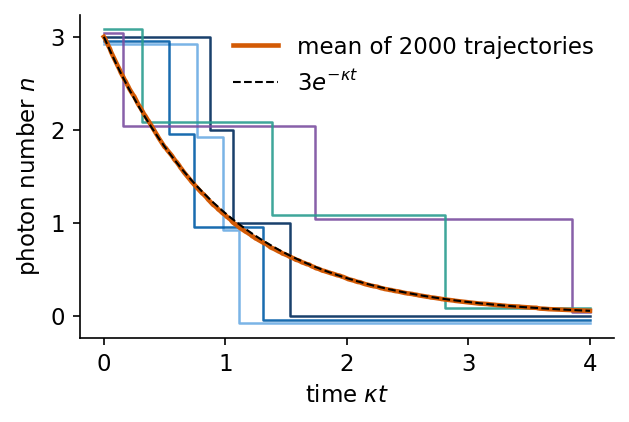

In [9]:
@partial(jax.jit, static_argnums=(2,))
def loss_only(key, psi0, steps):
    # photon number <n> along one trajectory with loss only
    def body(psi, k):
        psi, _ = loss_step(k, psi)
        return psi, jnp.sum(NVEC * jnp.abs(psi)**2)
    _, ns = lax.scan(body, psi0, jax.random.split(key, steps))
    return ns

B_demo, steps_demo = 2000, 400
FOCK3 = jnp.zeros(N, CDTYPE).at[3].set(1.0)
nt = jax.vmap(lambda k: loss_only(k, FOCK3, steps_demo))(jax.random.split(jax.random.PRNGKey(0), B_demo))
nt = np.concatenate([np.full((B_demo, 1), 3.0), np.asarray(nt)], axis=1).T     # (time, trajectory)
tt = dt_s * np.arange(steps_demo + 1)
print(f"<n> at t = 1/kappa: trajectories {nt[100].mean():.3f} +- {nt[100].std()/np.sqrt(B_demo):.3f}, formula 3 exp(-1) = {3*np.exp(-1):.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    for b, c in zip(range(5), (UJSky, UJBlue, UJNavy, "#7B4FA0", "#2A9D8F")):
        ax.step(tt, nt[:, b] + 0.04 * (b - 2), where="post", color=c, lw=1.2, alpha=0.9)
    ax.plot(tt, nt.mean(1), color=DSOrange, lw=2.2, label=rf"mean of {B_demo} trajectories")
    ax.plot(tt, 3 * np.exp(-kappa * tt), color="k", lw=1, ls="--", label=r"$3e^{-\kappa t}$")
    ax.set_xlabel(r"time $\kappa t$"); ax.set_ylabel(r"photon number $n$")
    ax.set_yticks([0, 1, 2, 3]); ax.legend(loc="upper right")
    save(fig, "fig_lab053_jumps"); plt.show()

The figure shows five single trajectories, shifted vertically by a few hundredths so that they do not hide each other, and the mean of 2000 trajectories. Every trajectory is a staircase with random step times, and only the mean follows the smooth exponential decay. At $t=1/\kappa$ the mean is 1.083 with a statistical error of about 0.02, against $3e^{-1}=1.104$ from the formula. The random jumps of single runs and the smooth decay of the average are two views of the same photon loss.

With a drive and loss together, a coherent state stays coherent, since $\hat a|\alpha\rangle=\alpha|\alpha\rangle$ leaves it unchanged under a jump. The drive increases the amplitude at the rate $\varepsilon$, and the loss shrinks it at the rate $\kappa/2$, half the decay rate of the photon number $|\alpha|^2$. The amplitude obeys $\dot\alpha=\varepsilon-\kappa\alpha/2$ and settles at $\alpha=2\varepsilon/\kappa$. A constant drive with $\varepsilon=\kappa/2$ therefore holds the cavity at $\bar n=1$ and reaches $P(1)=e^{-1}$ after a few times $1/\kappa$, the best value of any constant drive without a meter. Photon counting on the leaked light does not help either. A jump leaves a coherent state unchanged, and an interval without a jump only shrinks its amplitude, so the state stays coherent whatever the clicks. A drive steered by the clicks produces a mixture of coherent states, with $P(1)\le e^{-1}$. The scan of constant drives below confirms the value $e^{-1}$ numerically.

<hr/>
## 4. A noisy photon-number meter

Following the source we give the controller a weak measurement of the photon number inside the cavity. Such a measurement leaves the photon number unchanged and is called quantum nondemolition (QND). In circuit quantum electrodynamics it is made with a qubit or a second mode whose frequency shifts with the photon number of the cavity. We model it in discrete time. Every $\Delta t$ the meter shows a number
$$x_t=n+\sigma\,\xi_t,\qquad \xi_t\sim\mathcal N(0,1),$$
where $\xi_t$ is a random number from the normal distribution with mean zero and variance one, and $\sigma$ is the noise of a single reading. To generate a reading we draw a photon number $n$ with the probability $|\psi_n|^2$ and add the noise. The reading then has the distribution $p(x)=\sum_n|\psi_n|^2\,e^{-(x-n)^2/(2\sigma^2)}/\sqrt{2\pi\sigma^2}$ predicted by quantum mechanics. The drawn number $n$ only generates the reading, and the state changes through the update by Bayes' rule that follows. The probability $|\psi_n|^2$ of each Fock state is multiplied by the likelihood $p(x_t|n)\propto e^{-(x_t-n)^2/(2\sigma^2)}$ of the reading, so the amplitude is multiplied by its square root,
$$\psi_n\ \to\ \frac{1}{\mathcal N_t}\,\psi_n\,\exp\!\Big(-\frac{(x_t-n)^2}{4\sigma^2}\Big),$$
with the normalisation $\mathcal N_t$. Photon numbers close to the reading gain weight and distant ones lose it. For a large $\sigma$ one reading changes the state little, and many readings together pin down the photon number. This is the nonlinear element of the model, since the update depends on the random reading and the normalisation $\mathcal N_t$ depends on the state.

We use $\Delta t=0.05/\kappa$ and $\sigma=1$. One reading cannot tell an empty cavity from one photon reliably. The cell computes the error of the rule "one photon if $x_t>1/2$", which is the probability $\Phi(-1/(2\sigma))$ that the noise crosses half the distance between the two values, with $\Phi$ the cumulative normal distribution. Averaging $k$ readings lowers the noise to $\sigma/\sqrt k$ and the error to $\Phi(-\sqrt k/(2\sigma))$. The cell also defines the Bayes update and the meter.

In [10]:
dt = 0.05                    # time between meter readings and agent decisions, units 1/kappa
nsub = int(round(dt / dt_s)) # physics steps per decision
sigma = 1.0                  # noise of one meter reading
for k in (1, 4, 10):
    print(f"error of telling |0> from |1> with {k:2d} averaged readings: {norm.cdf(-0.5*np.sqrt(k)/sigma):.3f}")
NUMBERS.update(dict(dt=dt, sigma=sigma, err1=float(norm.cdf(-0.5/sigma)), err4=float(norm.cdf(-1.0/sigma))))

def meter_update(psi, x):
    # Bayes update after the reading x: psi_n -> psi_n exp(-(x - n)^2 / (4 sigma^2)) / Z
    return normalize(psi * jnp.exp(-(x - NVEC)**2 / (4 * sigma**2)))

def meter(key, psi):
    # one reading x = n + sigma*xi, with n drawn with probability |psi_n|^2, and the Bayes update of the state
    k1, k2 = jax.random.split(key)
    n_drawn = jax.random.categorical(k1, jnp.log(jnp.abs(psi)**2 + 1e-300))
    x = n_drawn + sigma * jax.random.normal(k2)
    return meter_update(psi, x), x

error of telling |0> from |1> with  1 averaged readings: 0.309
error of telling |0> from |1> with  4 averaged readings: 0.159
error of telling |0> from |1> with 10 averaged readings: 0.057


One reading misidentifies an empty cavity and a single photon with the probability 0.309, four averaged readings with 0.159 and ten with 0.057. A single Bayes update can again be followed with pen and paper. We take $(|0\rangle+|1\rangle)/\sqrt2$ and the reading $x=1$. The amplitude of $|1\rangle$ is multiplied by $e^{0}=1$ and that of $|0\rangle$ by $e^{-1/4}$, so after normalisation $P(1)=1/(1+e^{-1/2})$.

In [11]:
psi_x1 = meter_update(psi_plus, 1.0)
print(f"P(1) after the reading x = 1: {float(jnp.abs(psi_x1[1])**2):.4f}   (1 / (1 + exp(-1/2)) = {1/(1 + np.exp(-0.5)):.4f})")
print(f"P(1) after the reading x = 0: {float(jnp.abs(meter_update(psi_plus, 0.0)[1])**2):.4f}")


P(1) after the reading x = 1: 0.6225   (1 / (1 + exp(-1/2)) = 0.6225)
P(1) after the reading x = 0: 0.3775


A reading at 1 raises the probability of one photon from 0.5 to 0.62, and a reading at 0 lowers it by the same amount to 0.38. One reading moves the state only partly, as expected for $\sigma=1$.

Repeated readings turn a coherent state into a Fock state. We start three trajectories in the coherent state with $\bar n=1$ and apply the meter alone, without loss and drive. The probability of one photon starts at $e^{-1}$ and ends at 0 or 1, and over many trajectories it ends at 1 with the probability $P(1)=e^{-1}$, as quantum mechanics requires. The meter can thus create a one-photon state, but only by chance. The task of the feedback is to make this chance large and to refill the cavity after each loss.

fraction of trajectories ending in |1> after 60 readings: 0.369 (exp(-1) = 0.368)
average of P(1) over trajectories after 60 readings: 0.369


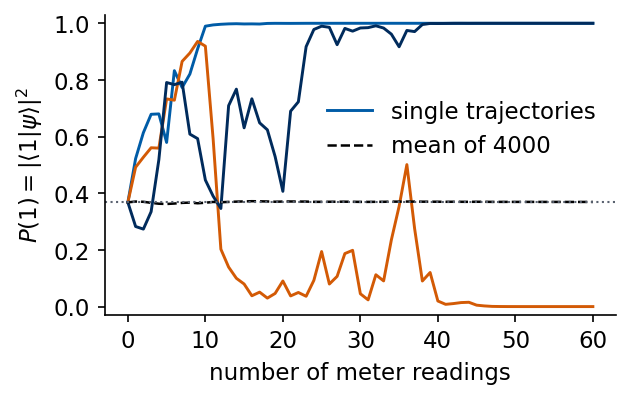

In [12]:
alpha0 = 1.0
COH = _expm_herm(alpha0 * HD1, 1.0) @ VAC        # coherent state with alpha = 1, nbar = 1
B_m, R_m = 4000, 60

@jax.jit
def meter_only(key):
    # P(1) along one trajectory of R_m meter readings, without drive and loss
    def body(psi, k):
        psi, _ = meter(k, psi)
        return psi, jnp.abs(psi[1])**2
    _, p1 = lax.scan(body, COH, jax.random.split(key, R_m))
    return p1

P1_hist = np.asarray(jax.vmap(meter_only)(jax.random.split(jax.random.PRNGKey(3), B_m))).T
P1_hist = np.concatenate([np.full((1, B_m), float(np.abs(COH[1])**2)), P1_hist])     # (reading, trajectory)
frac_one = float(np.mean(P1_hist[-1] > 0.5))
print(f"fraction of trajectories ending in |1> after {R_m} readings: {frac_one:.3f} (exp(-1) = {np.exp(-1):.3f})")
print(f"average of P(1) over trajectories after {R_m} readings: {P1_hist[-1].mean():.3f}")
NUMBERS["meter_frac_one"] = frac_one

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6))
    picks = [np.where(P1_hist[-1] > 0.99)[0][0], np.where(P1_hist[-1] < 0.01)[0][0], np.where(P1_hist[-1] > 0.99)[0][1]]
    for b, c in zip(picks, (UJBlue, DSOrange, UJNavy)):
        ax.plot(np.arange(R_m + 1), P1_hist[:, b], color=c, lw=1.4, label="single trajectories" if b == picks[0] else None)
    ax.plot(np.arange(R_m + 1), P1_hist.mean(1), color="k", ls="--", lw=1.2, label=f"mean of {B_m}")
    ax.axhline(np.exp(-1), color=UJGray, ls=":", lw=1)
    ax.set_xlabel("number of meter readings"); ax.set_ylabel(r"$P(1)=|\langle1|\psi\rangle|^2$")
    ax.set_ylim(-0.03, 1.03); ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.62))
    save(fig, "fig_lab053_meter"); plt.show()

The three coloured curves are single trajectories and the dashed curve the mean over 4000 trajectories, with $e^{-1}$ marked by the dotted line. Each trajectory ends at $P(1)=0$ or $1$. The fraction that ends at one photon is 0.369, equal to $e^{-1}=0.368$ within the statistical error of about 0.008, and the mean of $P(1)$ stays at $e^{-1}$ after every reading. The meter alone thus sorts the trajectories into Fock states, with the odds set by the initial state.

The full model of one decision interval $\Delta t$ is now complete. The drive chosen for the interval acts together with the loss for $\Delta t/\Delta t_{\rm s}=5$ physics steps, each a short drive rotation followed by the loss rule, and then the meter is read once. The agent receives the readings $x_t$ only. It never sees the state $|\psi\rangle$, the jumps or the photon number. In the cell below `drive_unitaries` computes the propagator $e^{-i\hat{\mathcal H}_{\rm d}\Delta t_{\rm s}}$ for each drive strength, and `cavity_step` applies the drive and the loss rule alternately, a splitting of the two processes whose error is of order $\Delta t_{\rm s}$, and then reads the meter. The sketch shows the whole loop.

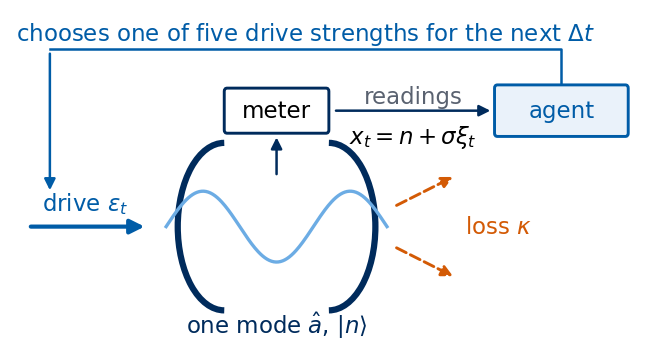

In [13]:
def drive_unitaries(eps_values):
    # exp(-i H_d dt_s) with H_d = i eps (a^dag - a), one N x N propagator per drive strength
    return jnp.stack([_expm_herm(e * HD1, dt_s) for e in eps_values])

def cavity_step(key_phys, key_meter, psi, U):
    # one decision interval dt: nsub physics steps of drive and loss, then one meter reading
    def substep(psi, k):
        psi, _ = loss_step(k, U @ psi)
        return psi, None
    psi, _ = lax.scan(substep, psi, jax.random.split(key_phys, nsub))
    return meter(key_meter, psi)

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.9))
    ax.set_xlim(0, 11); ax.set_ylim(0.1, 5.3); ax.axis("off")
    # mirrors and mode
    for x0, th in ((3.0, (90, 270)), (6.0, (-90, 90))):
        ax.add_patch(Arc((x0 + (0.6 if x0 < 4 else -0.6), 2.0), 1.6, 2.6, theta1=th[0], theta2=th[1], lw=3, color=UJNavy))
    xs_ = np.linspace(2.6, 6.4, 200)
    ax.plot(xs_, 2.0 + 0.55 * np.sin(np.pi * (xs_ - 2.6) / 3.8 * 3), color=UJSky, lw=1.6)
    ax.text(4.5, 0.35, r"one mode $\hat a$, $|n\rangle$", ha="center", fontsize=11, color=UJNavy)
    # drive
    ax.add_patch(FancyArrowPatch((0.2, 2.0), (2.3, 2.0), arrowstyle="-|>", mutation_scale=14, color=UJBlue, lw=2))
    ax.text(1.2, 2.25, r"drive $\varepsilon_t$", ha="center", fontsize=11, color=UJBlue)
    # loss
    for dy in (-0.5, 0.5):
        ax.add_patch(FancyArrowPatch((6.5, 2.0 + dy * 0.6), (7.6, 2.0 + dy * 1.6), arrowstyle="-|>", mutation_scale=11, color=DSOrange, lw=1.4, ls="--"))
    ax.text(7.75, 2.0, r"loss $\kappa$", ha="left", va="center", fontsize=11, color=DSOrange)
    # meter
    ax.add_patch(FancyBboxPatch((3.65, 3.5), 1.7, 0.6, boxstyle="round,pad=0.05", fc="white", ec=UJNavy, lw=1.4))
    ax.text(4.5, 3.8, "meter", ha="center", va="center", fontsize=11)
    ax.add_patch(FancyArrowPatch((4.5, 2.75), (4.5, 3.45), arrowstyle="-|>", mutation_scale=11, color=UJNavy, lw=1.2))
    # readings to the agent
    ax.add_patch(FancyArrowPatch((5.45, 3.8), (8.25, 3.8), arrowstyle="-|>", mutation_scale=11, color=UJNavy, lw=1.2))
    ax.text(6.85, 3.92, "readings", ha="center", fontsize=11, color=UJGray)
    ax.text(6.85, 3.3, r"$x_t=n+\sigma\xi_t$", ha="center", fontsize=11)
    # agent
    ax.add_patch(FancyBboxPatch((8.3, 3.45), 2.2, 0.7, boxstyle="round,pad=0.05", fc="#EAF2FA", ec=UJBlue, lw=1.4))
    ax.text(9.4, 3.8, "agent", ha="center", va="center", fontsize=11, color=UJBlue)
    # feedback: agent -> drive
    ax.plot([9.4, 9.4, 0.6], [4.22, 4.75, 4.75], color=UJBlue, lw=1.2)
    ax.add_patch(FancyArrowPatch((0.6, 4.75), (0.6, 2.5), arrowstyle="-|>", mutation_scale=11, color=UJBlue, lw=1.2))
    ax.text(5.0, 4.9, r"chooses one of five drive strengths for the next $\Delta t$", ha="center", fontsize=11, color=UJBlue)
    save(fig, "fig_lab053_setup"); plt.show()

<hr/>
## 5. The best constant drive

Before training we compute what a drive without feedback achieves in the same model. An episode is one run of the cavity from the empty state. It lasts $T\Delta t=5/\kappa$, that is $T=100$ decisions. The figure of merit is the probability of one photon averaged over the episode,
$$\bar P_1=\frac1T\sum_{t=1}^{T}\langle1|\hat\rho_t|1\rangle ,$$
where $\hat\rho_t$ is the density matrix after decision $t$, the average of $|\psi_t\rangle\langle\psi_t|$ over trajectories.
For a constant drive the readings are not used, and the average over trajectories is the density matrix. Our trajectory rules average to an exact linear map of $\hat\rho$. The loss step gives $\hat\rho\to\hat K_0\hat\rho\hat K_0+\kappa\Delta t_{\rm s}\,\hat a\hat\rho\hat a^\dagger$ with $\hat K_0=\sqrt{1-\kappa\Delta t_{\rm s}\hat n}$, and the averaged meter reading multiplies the element $\rho_{nm}$ by $e^{-(n-m)^2/(8\sigma^2)}$. The meter thus destroys the coherence between photon numbers, which also slows down the drive. The factor $e^{-(n-m)^2/(8\sigma^2)}$ is the average of the phase rotation $e^{-i\varphi\hat n}$ over a Gaussian random phase $\varphi$ with variance $1/(4\sigma^2)$, so the averaged meter turns a coherent state into a mixture of coherent states. A drive that ignores the readings therefore leaves the cavity in a mixture of coherent states, with $P(1)\le e^{-1}$ and $Q\ge0$, even with the meter on. We scan the drive strength with the meter on and with the meter switched off. Strong constant drives push the cavity to many photons, up to $\bar n=(2\varepsilon/\kappa)^2=64$ for $\varepsilon=4\kappa$ without the meter, far above the 12 levels kept so far. We therefore run the scan both with $N=12$, the space in which the agent acts, and with 100 levels. The plotted curves are the 100-level ones, and the cell prints the largest population of the two highest levels to show that 100 levels suffice.

meter on : best constant drive eps = 1.35 kappa, episode average P(1) = 0.258
meter off: best constant drive eps = 0.70 kappa, episode average P(1) = 0.292
100 levels: best eps = 1.35 (meter on), 0.70 (meter off), P(1) = 0.258 and 0.292
100 levels: largest final population of the two highest levels in the scan 4.7e-20
12 levels against 100: largest difference of the episode average up to eps = 1 kappa 3.2e-06
meter off, eps = kappa/2, P(1) at t = 20/kappa: 0.3697  (exp(-1) = 0.3679)


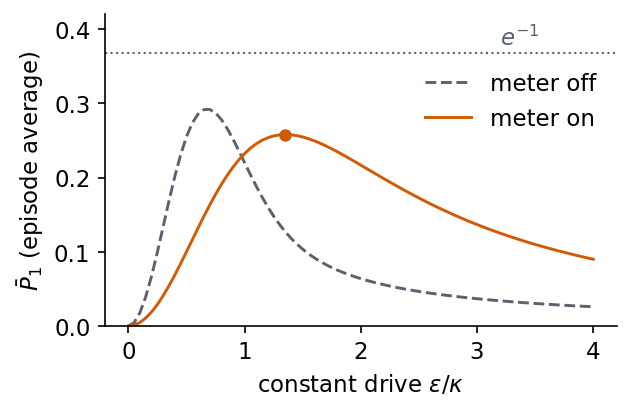

In [14]:
T = 100                      # decisions per episode, episode length T*dt = 5/kappa
DEPHASE = jnp.exp(-(NVEC[:, None] - NVEC[None, :])**2 / (8 * sigma**2))

def make_rho_constant_drive(Nf):
    """Exact average over trajectories for a constant drive, in a Fock space with Nf levels.
    Returns rho_constant_drive(eps, meter_on, steps) -> (P(1) after each decision, final rho)."""
    _, a_f, ad_f = fock_tools(Nf)
    HD_f = dense(lambda p: 1j * (ad_f(p) - a_f(p)), Nf)              # H_d for eps = 1
    K_f = kraus_from_jump(dense(a_f, Nf), kappa * dt_s)               # photon-loss pair K0, K1
    n_f = jnp.arange(Nf, dtype=RDTYPE)
    D_f = jnp.exp(-(n_f[:, None] - n_f[None, :])**2 / (8 * sigma**2))  # averaged meter reading
    @partial(jax.jit, static_argnums=(1, 2))
    def rho_constant_drive(eps, meter_on=True, steps=T):
        U1 = _expm_herm(eps * HD_f, dt_s)
        def substep(rho, _):                                          # drive, then loss: K0 rho K0^dag + K1 rho K1^dag
            return apply_kraus_dm_mode(U1 @ rho @ U1.conj().T, K_f), None
        def decision(rho, _):
            rho, _ = lax.scan(substep, rho, None, length=nsub)
            rho = rho * D_f if meter_on else rho
            return rho, jnp.real(rho[1, 1])
        rho0 = jnp.zeros((Nf, Nf), CDTYPE).at[0, 0].set(1.0)
        rho, P1 = lax.scan(decision, rho0, None, length=steps)
        return P1, rho
    return rho_constant_drive

rho_constant_drive = make_rho_constant_drive(N)          # the space of the agent, N = 12 levels
N_BIG = 100
rho_constant_drive_big = make_rho_constant_drive(N_BIG)  # convergence check of the Fock-space cut

eps_scan = np.round(np.arange(0.0, 4.01, 0.05), 2)
def scan(fn, meter_on):
    P1, rho = jax.vmap(lambda e: fn(e, meter_on))(jnp.asarray(eps_scan))
    top = jnp.real(jnp.diagonal(rho, axis1=1, axis2=2))[:, -2:].sum(-1)   # population of the two highest levels
    return np.asarray(P1.mean(1)), np.asarray(top)
scan_on, _ = scan(rho_constant_drive, True)
scan_off, _ = scan(rho_constant_drive, False)
scan_on_big, top_on_big = scan(rho_constant_drive_big, True)
scan_off_big, top_off_big = scan(rho_constant_drive_big, False)
eps_best = float(eps_scan[np.argmax(scan_on)]); P1_const_best = float(scan_on.max())
eps_best_off = float(eps_scan[np.argmax(scan_off)])
P1_off_late = float(rho_constant_drive(0.5, False, 400)[0][-1])
print(f"meter on : best constant drive eps = {eps_best:.2f} kappa, episode average P(1) = {P1_const_best:.3f}")
print(f"meter off: best constant drive eps = {eps_best_off:.2f} kappa, episode average P(1) = {scan_off.max():.3f}")
print(f"{N_BIG} levels: best eps = {eps_scan[np.argmax(scan_on_big)]:.2f} (meter on), {eps_scan[np.argmax(scan_off_big)]:.2f} (meter off), "
      f"P(1) = {scan_on_big.max():.3f} and {scan_off_big.max():.3f}")
print(f"{N_BIG} levels: largest final population of the two highest levels in the scan {max(top_on_big.max(), top_off_big.max()):.1e}")
print(f"{N} levels against {N_BIG}: largest difference of the episode average up to eps = 1 kappa "
      f"{np.max(np.abs(np.r_[scan_on - scan_on_big, scan_off - scan_off_big][np.r_[eps_scan, eps_scan] <= 1.0])):.1e}")
print(f"meter off, eps = kappa/2, P(1) at t = 20/kappa: {P1_off_late:.4f}  (exp(-1) = {np.exp(-1):.4f})")
NUMBERS.update(dict(eps_best=eps_best, P1_const_best=P1_const_best, eps_best_off=eps_best_off,
                    P1_const_best_off=float(scan_off.max()), P1_off_late=P1_off_late))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.7))
    ax.plot(eps_scan, scan_off_big, color=UJGray, ls="--", label="meter off")
    ax.plot(eps_scan, scan_on_big, color=C_CONST, label="meter on")
    ax.plot([eps_best], [P1_const_best], "o", color=C_CONST, ms=5)
    ax.axhline(np.exp(-1), color=UJGray, ls=":", lw=1); ax.text(3.2, np.exp(-1) + 0.01, r"$e^{-1}$", color=UJGray, fontsize=11)
    ax.set_xlabel(r"constant drive $\varepsilon/\kappa$"); ax.set_ylabel(r"$\bar P_1$ (episode average)")
    ax.set_ylim(0, 0.42); ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.88))
    save(fig, "fig_lab053_constant"); plt.show()


The figure shows the episode average $\bar P_1$ as a function of the constant drive strength, with the dot at the best drive with the meter on. Without the meter the best constant drive for the episode average is $\varepsilon=0.7\kappa$, above the value $\kappa/2$ that is best at long times, because the cavity starts empty and a stronger drive fills it faster. At long times the drive $\varepsilon=\kappa/2$ brings $P(1)$ to 0.3697, which is $e^{-1}=0.3679$ up to the error of the time step $\Delta t_{\rm s}$. With the meter on, the best constant drive is $\varepsilon=1.35\kappa$ and reaches the episode average 0.258, less than without the meter, because the meter removes the coherence that the drive builds up. The best drives and their values are the same with 12 and with 100 levels. Up to $\varepsilon=\kappa$ the two spaces agree to $3\times10^{-6}$, and larger differences appear only for strong drives, far from the optimum. With 100 levels the two highest levels hold at most $5\times10^{-20}$, so the plotted curves are free of the cut. The value 0.258 is the reference for the trained agent, the best that a drive without feedback can do in the model in which the agent acts.

### Checks of the simulation

Every building block of the simulation is checked against an exact reference. The drive propagators must be unitary. The drive with loss and without the meter must settle in the coherent state with $\alpha=2\varepsilon/\kappa$, whose populations are Poisson. One meter reading averaged over its outcomes must multiply $\rho_{nm}$ by $e^{-(n-m)^2/(8\sigma^2)}$. The full trajectory simulation of a decision interval with a constant drive must reproduce, within its statistical error, the density-matrix map used for the constant drive. The cell prints the largest deviation in each test. The first and third tests agree to round-off and to the statistical error. The steady state of the second test deviates from the Poisson populations by a few times $10^{-3}$, the error of the first-order time step $\Delta t_{\rm s}=0.01/\kappa$, which is small against all differences discussed below. The fourth test agrees within less than two standard errors.

In [15]:
# 1. unitarity of the drive propagators of one physics step
U_test = drive_unitaries([0.5, 1.0, 4.0])
print("1. max |U^dag U - 1| of the drive propagators:", float(jnp.max(jnp.abs(jnp.einsum("kba,kbc->kac", U_test.conj(), U_test) - jnp.eye(N)))))

# 2. drive + loss without meter: steady state = coherent state with alpha = 2 eps / kappa (Poisson populations)
for eps in (0.25, 0.5):
    _, rho_ss = rho_constant_drive(eps, False, 400)          # t = 20 / kappa
    dev = np.max(np.abs(np.real(np.diag(np.asarray(rho_ss))) - poisson((2 * eps / kappa)**2, N)))
    print(f"2. eps = {eps}: max |P(n) - Poisson(nbar = {(2*eps/kappa)**2:g})| at t = 20/kappa: {dev:.1e}")

# 3. meter averaged over its outcomes = dephasing of rho_nm by exp(-(n-m)^2 / (8 sigma^2))
B_chk = 40000
psis = jax.vmap(lambda k: meter(k, COH)[0])(jax.random.split(jax.random.PRNGKey(21), B_chk))
rho_avg = jnp.einsum("ba,bc->ac", psis, psis.conj()) / B_chk
rho_exact = jnp.outer(COH, COH.conj()) * DEPHASE
print(f"3. meter: max |rho(trajectories) - rho(exact)| = {float(jnp.max(jnp.abs(rho_avg - rho_exact))):.4f} "
      f"(statistical error about {1/np.sqrt(B_chk):.4f})")

# 4. full decision interval: trajectories of cavity_step against the density-matrix map, constant drive
@partial(jax.jit, static_argnums=(2,))
def populations_constant(key, U, steps):
    def body(psi, k):
        k1, k2 = jax.random.split(k)
        psi, _ = cavity_step(k1, k2, psi, U)
        return psi, None
    psi, _ = lax.scan(body, VAC, jax.random.split(key, steps))
    return jnp.abs(psi)**2
steps_chk = 20
U_b = drive_unitaries([eps_best])[0]
P_traj = jax.vmap(lambda k: populations_constant(k, U_b, steps_chk))(jax.random.split(jax.random.PRNGKey(22), B_chk))
P_dm = np.real(np.diag(np.asarray(rho_constant_drive(eps_best, True, steps_chk)[1])))
z = np.abs(np.asarray(P_traj.mean(0)) - P_dm) / (np.asarray(P_traj.std(0)) / np.sqrt(B_chk) + 1e-12)
print(f"4. cavity_step, eps = {eps_best}, t = {steps_chk*dt:g}/kappa: max |P(n) trajectories - P(n) density matrix| = "
      f"{np.max(np.abs(np.asarray(P_traj.mean(0)) - P_dm)):.4f}, largest deviation in standard errors {z[:6].max():.1f}")

1. max |U^dag U - 1| of the drive propagators: 2.55351295663786e-15
2. eps = 0.25: max |P(n) - Poisson(nbar = 0.25)| at t = 20/kappa: 2.7e-03
2. eps = 0.5: max |P(n) - Poisson(nbar = 1)| at t = 20/kappa: 3.7e-03


3. meter: max |rho(trajectories) - rho(exact)| = 0.0014 (statistical error about 0.0050)


4. cavity_step, eps = 1.35, t = 1/kappa: max |P(n) trajectories - P(n) density matrix| = 0.0033, largest deviation in standard errors 1.6


<hr/>
## 6. The control task for reinforcement learning

Reinforcement learning describes a loop between an agent and an environment. At each decision the agent receives an observation of the environment, chooses an action, and then receives a reward, a number that measures how good the result of the action is. A run of $T$ decisions is an episode, and the sum of the rewards over an episode is the return. The rule by which the agent chooses its actions is the policy, and learning means changing the policy so that the expected return grows. In our task the environment is the simulated cavity with its meter. At each decision $t$ the agent receives the observation $o_t=(x_{t-9},\dots,x_t)$, the last ten meter readings, with zeros before the first reading. It chooses an action $a_t$, one of the five drive strengths $\varepsilon\in\{0,\,0.5,\,1,\,2,\,4\}\,\kappa$, which then acts for the interval $\Delta t$. The reward is the probability of one photon after the interval, $r_t=|\langle1|\psi_t\rangle|^2$, and the return of an episode is $G=\sum_{t=1}^T r_t$, which is $T\bar P_1$.

The simulation knows the full state $|\psi_t\rangle$, including the photon losses that nobody observes, and uses it to compute the reward. The agent uses the readings only. Averaged over the unobserved losses, the reward equals $\langle1|\hat\rho_t|1\rangle$ of the state conditioned on the readings, so the expected return is the same as with the reward computed from that conditioned state.

The policy $\pi_\theta(a|o)$ is a small network with parameters $\theta$. It maps the ten readings through two hidden layers of 64 units to five numbers $z_a$, the logits,
$$\begin{aligned}\mathbf h_1&=\tanh(W_1 o+\mathbf b_1),\qquad \mathbf h_2=\tanh(W_2\mathbf h_1+\mathbf b_2),\\ z(o)&=W_3\mathbf h_2+\mathbf b_3,\end{aligned}$$
where the weight matrices $W_i$ and the bias vectors $\mathbf b_i$ together form $\theta$, and $\tanh$ acts on each component. This gives $(10\cdot64+64)+(64\cdot64+64)+(64\cdot5+5)=5189$ parameters. The softmax turns the logits into probabilities,
$$\pi_\theta(a|o)=\frac{e^{z_a(o)}}{\sum_{b}e^{z_b(o)}} .$$
If all logits are equal, every action has the probability $1/5$. The last layer starts with small weights, so the untrained policy is close to this uniform choice.
The agent samples its action from these probabilities. The source uses the same type of network with the most recent measurement points as input. The cell below separates the environment (`env_reset`, `env_step`), the rollout of whole episodes for a batch of trajectories (`make_rollout`), and the agent (`init_mlp`, `mlp`, `agent_act`), and it draws the network.

layer sizes: [10, 64, 64, 5]  trainable parameters: 5189


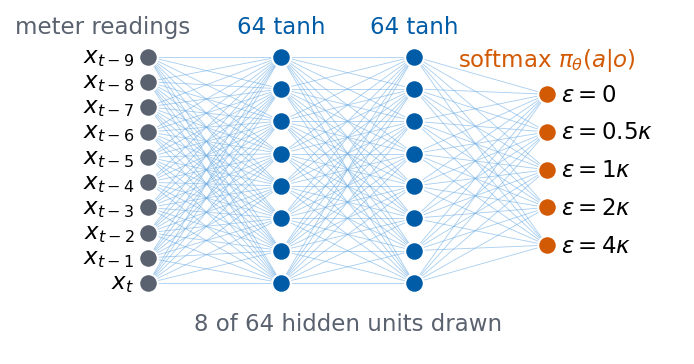

In [16]:
EPS_ACTIONS = np.array([0.0, 0.5, 1.0, 2.0, 4.0])     # drive strengths in units of kappa
NA, K_OBS, HID = len(EPS_ACTIONS), 10, 64
U_ACT = drive_unitaries(EPS_ACTIONS)                  # one propagator per action, for one physics step dt_s

# ---------------- environment: the cavity with its meter ----------------
def env_reset():
    """Empty cavity |0> and an observation window of K_OBS zeros."""
    return VAC, jnp.zeros(K_OBS)

def env_step(key, state, action, U_table):
    """One decision interval dt with the drive U_table[action].
    Returns the new state (psi, window of readings), the new reading x and the reward |<1|psi>|^2.
    The reward uses the full simulated state. The agent only ever receives the window of readings."""
    psi, window = state
    k_phys, k_met = jax.random.split(key)
    psi, x = cavity_step(k_phys, k_met, psi, U_table[action])
    window = jnp.concatenate([window[1:], jnp.atleast_1d(x)])
    return (psi, window), x, jnp.abs(psi[1])**2

def make_rollout(act_fn, U_table, record=False):
    """Compiled function (theta, keys) -> trajectories for a batch of random keys.
    act_fn(theta, key, window) is the controller: the agent, a constant drive or a threshold rule.
    Outputs, each with axes (trajectory, decision): observations, actions, rewards, readings
    and, with record=True, the Fock populations |psi_n|^2."""
    def one(theta, key):
        def decision(state, k):
            k_act, k_env = jax.random.split(k)
            obs = state[1]
            action = act_fn(theta, k_act, obs)
            state, x, r = env_step(k_env, state, action, U_table)
            out = (obs, action, r, x) + ((jnp.abs(state[0])**2,) if record else ())
            return state, out
        _, outs = lax.scan(decision, env_reset(), jax.random.split(key, T))
        return outs
    return jax.jit(lambda theta, keys: jax.vmap(one, in_axes=(None, 0))(theta, keys))

# ---------------- agent: the policy network ----------------
def init_mlp(key, sizes):
    """Weights with variance 1/fan_in; the last layer is scaled by 0.01, so the first policy is close to uniform."""
    params = []
    keys = jax.random.split(key, len(sizes) - 1)
    for i, (k, n_in, n_out) in enumerate(zip(keys, sizes[:-1], sizes[1:])):
        scale = (0.01 if i == len(sizes) - 2 else 1.0) / np.sqrt(n_in)
        params.append((scale * jax.random.normal(k, (n_in, n_out)), jnp.zeros(n_out)))
    return params

def mlp(params, x):
    """Logits z_a(o) of the policy, two tanh hidden layers."""
    for W, b in params[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = params[-1]
    return x @ W + b

def agent_act(params, key, window):
    """Sample an action from the softmax policy pi(a|o) = exp(z_a) / sum_b exp(z_b)."""
    return jax.random.categorical(key, mlp(params, window))

SIZES = [K_OBS, HID, HID, NA]
n_params = sum(W.size + b.size for W, b in init_mlp(jax.random.PRNGKey(0), SIZES))
print("layer sizes:", SIZES, " trainable parameters:", n_params)
NUMBERS.update(dict(n_params=n_params, K_obs=K_OBS, hidden=HID, n_actions=NA, eps_max=float(EPS_ACTIONS.max()), T=T))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.9))
    layers = [(0.0, 10, [rf"$x_{{t-{9-i}}}$" if i < 9 else r"$x_t$" for i in range(10)]),
              (1.6, 8, None), (3.2, 8, None), (4.8, 5, [r"$\varepsilon=0$" if e == 0 else rf"$\varepsilon={e:g}\kappa$" for e in EPS_ACTIONS])]
    pos = []
    for x0, m, labels in layers:
        ys = np.linspace(0.3, 2.7, m) if m > 5 else np.linspace(0.7, 2.3, m)
        pos.append([(x0, y) for y in ys[::-1]])
    for L in range(3):
        for p in pos[L]:
            for q in pos[L + 1]:
                ax.plot([p[0], q[0]], [p[1], q[1]], color=UJSky, lw=0.4, alpha=0.6, zorder=1)
    for L, (x0, m, labels) in enumerate(layers):
        for i, (x, y) in enumerate(pos[L]):
            ax.scatter([x], [y], s=80, color=[UJGray, UJBlue, UJBlue, DSOrange][L], edgecolors="white", zorder=3)
            if labels is not None:
                if L == 0: ax.text(x - 0.17, y, labels[i], ha="right", va="center", fontsize=11)
                else: ax.text(x + 0.17, y, labels[i], ha="left", va="center", fontsize=11)
    ax.text(1.6, 2.95, "64 tanh", ha="center", fontsize=11, color=UJBlue)
    ax.text(3.2, 2.95, "64 tanh", ha="center", fontsize=11, color=UJBlue)
    ax.text(2.4, -0.2, "8 of 64 hidden units drawn", ha="center", fontsize=11, color=UJGray)
    ax.text(4.8, 2.6, r"softmax $\pi_\theta(a|o)$", ha="center", fontsize=11, color=DSOrange)
    ax.text(-0.55, 2.95, "meter readings", ha="center", fontsize=11, color=UJGray)
    ax.set_xlim(-1.3, 6.4); ax.set_ylim(-0.4, 3.15); ax.axis("off")
    save(fig, "fig_lab053_network"); plt.show()

The network has the 5189 parameters counted above. The figure shows its structure, with the ten readings on the left, two hidden layers of which 8 of the 64 units are drawn, and the five drive strengths on the right, whose probabilities the softmax returns.

### The policy gradient

We want to increase the expected return $\langle G\rangle=\sum_\tau P_\theta(\tau)\,G(\tau)$. Here $\tau$ is one history of an episode, the full sequence of readings, photon losses and actions, $P_\theta(\tau)$ is its probability under the policy with parameters $\theta$, and $G(\tau)$ its return. Using $\nabla_\theta P_\theta=P_\theta\nabla_\theta\ln P_\theta$,
$$\nabla_\theta\langle G\rangle=\big\langle G\,\nabla_\theta\ln P_\theta(\tau)\big\rangle=\Big\langle G\sum_{t}\nabla_\theta\ln\pi_\theta(a_t|o_t)\Big\rangle .$$
The probability of a history is a product of physics probabilities, for the readings and the losses, and of policy probabilities. Only the policy depends on $\theta$, so the physics drops out of the logarithm's gradient, and the gradient is estimated from simulated or measured histories without a model of the cavity. This estimator is REINFORCE [R. J. Williams, Mach. Learn. **8**, 229 (1992), [doi:10.1007/BF00992696](https://doi.org/10.1007/BF00992696)].

As an analogy, the same score-function identity appears in the fluctuation formula of statistical mechanics. For the Boltzmann distribution $p_\beta(E)=e^{-\beta E}/Z$ we have $\partial_\beta\ln p_\beta=-(E-\langle E\rangle)$, and therefore
$$\partial_\beta\langle E\rangle=\langle E\,\partial_\beta\ln p_\beta\rangle=-\mathrm{Var}\,E .$$
The softmax policy has the form of a Boltzmann distribution over the actions, with the energies $-z_a$ at unit temperature, and the parameters $\theta$ enter through these energies as $\beta$ enters $p_\beta$.

Since $\langle\nabla_\theta\ln\pi_\theta\rangle=\sum_a\nabla_\theta\pi_\theta(a|o)=\nabla_\theta 1=0$, any constant $b$ can be subtracted from $G$ without changing the average gradient, and a baseline close to the mean return reduces the noise of the estimate, in the same way as $\langle E\rangle$ appears in $\partial_\beta\ln p_\beta$. We use two standard refinements. An action affects only later rewards, so $\ln\pi_\theta(a_t|o_t)$ is multiplied by the reward to go $G_t=\sum_{t'\ge t}r_{t'}$, and the baseline $b_t$ is the batch average of $G_t$ at the same $t$. With 256 trajectories in a batch, the contribution of one trajectory to its own baseline is small, and the bias it causes is of order $1/256$.

<hr/>
## 7. Training with REINFORCE

One training epoch here means one batch of trajectories and one update of the parameters. Each epoch simulates a batch of 256 trajectories of $T=100$ decisions with the current policy, computes the rewards to go, and makes one step of the Adam optimiser [D. P. Kingma and J. Ba, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)], a gradient method that adapts the step size of each parameter, with the learning rate $3\times10^{-3}$, on the loss $-\frac{1}{T}\big\langle\sum_t (G_t-b_t)\ln\pi_\theta(a_t|o_t)\big\rangle$, whose gradient is the estimate above with the opposite sign. The trajectories of a batch are simulated in parallel with `jax.vmap`, and the whole epoch, simulation, gradient and Adam step, is one compiled function. The cell below defines the reward to go, the loss and one training epoch. Before training we check these pieces on small cases with known answers.

In [17]:
def reward_to_go(r):
    """G_t = sum_{t' >= t} r_t' along the decision axis 1."""
    return jnp.flip(jnp.cumsum(jnp.flip(r, 1), 1), 1)

EPOCHS, BATCH, LR = 150, 256, 3e-3
SEEDS = (0, 1, 2)
rollout_agent = make_rollout(agent_act, U_ACT)
opt = optax.adam(LR)

def reinforce_loss(params, obs, acts, adv):
    """-(1/T) < sum_t (G_t - b_t) ln pi(a_t|o_t) >; its gradient is minus the REINFORCE estimate."""
    logp = jnp.take_along_axis(jax.nn.log_softmax(mlp(params, obs)), acts[..., None], axis=-1)[..., 0]
    return -jnp.mean(jnp.sum(adv * logp, axis=1)) / T

def train_step(params, opt_state, key):
    """One epoch: a batch of trajectories with the current policy, then one Adam step."""
    obs, acts, rews, _ = rollout_agent(params, jax.random.split(key, BATCH))     # axes (B, T, ...)
    G = reward_to_go(rews)
    adv = G - G.mean(axis=0, keepdims=True)                                       # baseline b_t = batch mean of G_t
    grads = jax.grad(reinforce_loss)(params, obs, acts, adv)
    updates, opt_state = opt.update(grads, opt_state, params)
    freq = jnp.bincount(acts.ravel(), length=NA) / acts.size
    return optax.apply_updates(params, updates), opt_state, rews.mean(), freq


The first check is the reward to go of a three-step episode with the rewards $1,2,3$, which must be $(6,5,3)$. The second check is a problem with one decision, a fixed observation $o$ and a known reward $r(a)=(0,\,0.2,\,0.4,\,0.6,\,1)$ for the five actions. Its expected return $\langle G\rangle=\sum_a\pi_\theta(a|o)\,r(a)$ can be differentiated directly, and we compare this exact gradient with the REINFORCE estimate from 200000 sampled actions, computed with the same loss function as in training. The factor $T$ undoes the division by $T$ in the loss.

In [18]:
# reward to go of a three-step episode with the rewards 1, 2, 3: expected (6, 5, 3)
print("rewards to go of r = (1, 2, 3):", np.asarray(reward_to_go(jnp.array([[1.0, 2.0, 3.0]])))[0])

# REINFORCE on a one-decision problem with a known answer: fixed observation o, known reward r(a) per action,
# expected return <G> = sum_a pi(a|o) r(a), whose exact gradient jax.grad computes directly
from jax.flatten_util import ravel_pytree
r_toy = jnp.array([0.0, 0.2, 0.4, 0.6, 1.0])
o_toy = jnp.linspace(-1.0, 1.0, K_OBS)
p_toy = init_mlp(jax.random.PRNGKey(5), SIZES)
g_exact = ravel_pytree(jax.grad(lambda p: jnp.sum(jax.nn.softmax(mlp(p, o_toy)) * r_toy))(p_toy))[0]
B_toy = 200_000
a_toy = jax.random.categorical(jax.random.PRNGKey(6), mlp(p_toy, o_toy), shape=(B_toy,))
adv_toy = (r_toy[a_toy] - r_toy[a_toy].mean())[:, None]          # one decision, baseline = batch mean
obs_toy = jnp.broadcast_to(o_toy, (B_toy, 1, K_OBS))
g_est = -T * ravel_pytree(jax.grad(reinforce_loss)(p_toy, obs_toy, a_toy[:, None], adv_toy))[0]
print(f"relative difference |g_est - g_exact| / |g_exact| = {float(jnp.linalg.norm(g_est - g_exact) / jnp.linalg.norm(g_exact)):.3f}")
print(f"cosine between the two gradients = {float(g_est @ g_exact / (jnp.linalg.norm(g_est) * jnp.linalg.norm(g_exact))):.4f}")


rewards to go of r = (1, 2, 3): [6. 5. 3.]


relative difference |g_est - g_exact| / |g_exact| = 0.002
cosine between the two gradients = 1.0000


The rewards to go come out as $(6,5,3)$, and the sampled gradient differs from the exact one by 0.2 percent of its length, with a cosine of 1.0000 between the two vectors. The estimator therefore points in the direction that increases the expected return, without any derivative of the environment. We now train three networks with different random seeds for the initial weights and the trajectories, for 150 epochs each. The three runs advance together in one compiled program, and the printout shows the batch average of $P(1)$ for each seed and the frequencies of the five actions for seed 0.

In [19]:
# the independent training runs of all seeds advance together in one compiled program
train_step_seeds = jax.jit(jax.vmap(train_step))
params = jax.vmap(lambda k: init_mlp(k, SIZES))(jnp.stack([jax.random.PRNGKey(s_) for s_ in SEEDS]))
opt_state = jax.vmap(opt.init)(params)
keys = jnp.stack([jax.random.PRNGKey(100 + s_) for s_ in SEEDS])
curve, act_freq = [], []
t0 = time.time()
for ep in range(EPOCHS):
    keys, sub = jax.vmap(jax.random.split, out_axes=1)(keys)
    params, opt_state, r_mean, freq = train_step_seeds(params, opt_state, sub)
    curve.append(np.asarray(r_mean)); act_freq.append(np.asarray(freq))
    if ep % 25 == 0 or ep == EPOCHS - 1:
        print(f"epoch {ep:3d}  batch average P(1) per seed {np.round(curve[-1], 3)}  "
              f"action frequencies (seed 0) {np.round(act_freq[-1][0], 2)}  {time.time()-t0:5.1f} s")
train_time = time.time() - t0
curve, act_freq = np.array(curve), np.array(act_freq)          # axes (epoch, seed, ...)
params_seed = [jax.tree_util.tree_map(lambda p: p[i], params) for i in range(len(SEEDS))]
NUMBERS.update(dict(epochs=EPOCHS, batch=BATCH, seeds=len(SEEDS), train_time_s=round(train_time, 1),
                    curve_first=float(curve[0].mean()), curve_last20=curve[-20:].mean(0).tolist()))

epoch   0  batch average P(1) per seed [0.242 0.252 0.248]  action frequencies (seed 0) [0.2  0.2  0.21 0.2  0.2 ]    3.2 s


epoch  25  batch average P(1) per seed [0.452 0.438 0.447]  action frequencies (seed 0) [0.43 0.21 0.1  0.08 0.18]   26.3 s


epoch  50  batch average P(1) per seed [0.527 0.518 0.528]  action frequencies (seed 0) [0.57 0.08 0.06 0.05 0.25]   49.4 s


epoch  75  batch average P(1) per seed [0.535 0.547 0.535]  action frequencies (seed 0) [0.64 0.04 0.03 0.03 0.26]   72.3 s


epoch 100  batch average P(1) per seed [0.552 0.563 0.552]  action frequencies (seed 0) [0.64 0.04 0.03 0.03 0.27]   97.8 s


epoch 125  batch average P(1) per seed [0.561 0.572 0.557]  action frequencies (seed 0) [0.63 0.04 0.03 0.02 0.28]  125.0 s


epoch 149  batch average P(1) per seed [0.561 0.55  0.565]  action frequencies (seed 0) [0.65 0.03 0.02 0.02 0.28]  152.0 s


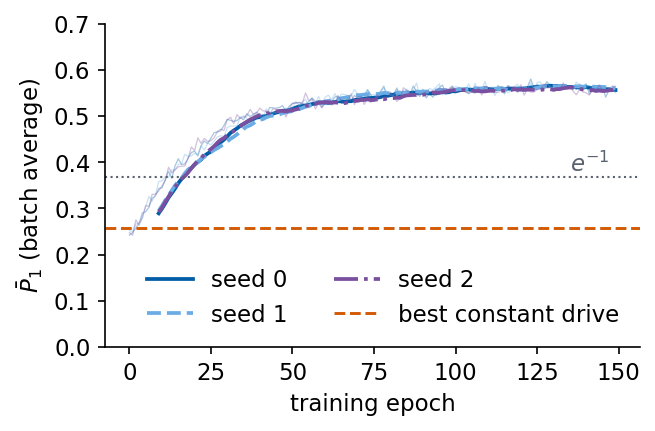

In [20]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    # one colour and one line style per seed (blue, light blue, purple), so that the seeds stay distinguishable
    for i, (c, ls) in enumerate(((UJBlue, "-"), (UJSky, "--"), ("#7B4FA0", "-."))):
        run = np.convolve(curve[:, i], np.ones(10) / 10, mode="valid")
        ax.plot(np.arange(EPOCHS), curve[:, i], color=c, lw=0.6, alpha=0.35)
        ax.plot(np.arange(9, EPOCHS), run, color=c, ls=ls, lw=1.8, label=f"seed {SEEDS[i]}")
    ax.axhline(P1_const_best, color=C_CONST, ls="--", lw=1.4, label="best constant drive")
    ax.axhline(np.exp(-1), color=UJGray, ls=":", lw=1); ax.text(EPOCHS * 0.9, np.exp(-1) + 0.012, r"$e^{-1}$", color=UJGray, fontsize=11)
    ax.set_xlabel("training epoch"); ax.set_ylabel(r"$\bar P_1$ (batch average)")
    ax.set_ylim(0, 0.7); ax.legend(loc="lower right", ncol=2)
    save(fig, "fig_lab053_learning"); plt.show()

The thin lines show the batch average $\bar P_1$ of every epoch and the thick lines its running mean over 10 epochs, with one colour and one line style per seed. The untrained network chooses the five drives with roughly equal probability, a randomly flickering drive, and reaches 0.247 at the first epoch, close to the best constant drive 0.258. Within a few tens of epochs the batch average of $P(1)$ rises above $e^{-1}$, which no drive without feedback can reach, and after about 100 epochs it levels off. The three seeds give nearly the same learning curve. The printed action frequencies of seed 0 show that the trained agent mostly switches between the two extreme actions, no drive and the strongest drive. The policy gradient alone, fed with rewards and readings, has turned a random drive into a feedback controller.

<hr/>
## 8. The trained agent

We test each of the three trained policies on 2000 new trajectories, drawn with random keys unused in training and with actions still sampled from $\pi_\theta$, and compare the time dependence of the probability of one photon with the best constant drive and with no drive. The constant-drive curve is the exact density-matrix average, and the cell also runs the best constant drive with 2000 trajectories as a further check of the simulation.

trained agent, seed 0: episode average P(1) = 0.562 +- 0.003, second half 0.595
trained agent, seed 1: episode average P(1) = 0.557 +- 0.002, second half 0.582
trained agent, seed 2: episode average P(1) = 0.566 +- 0.002, second half 0.592
best constant drive    : episode average P(1) = 0.258 (exact), 0.258 +- 0.002 (trajectories), second half 0.271
ratio agent / best constant drive, lowest and highest seed: 2.16, 2.19
largest population of the two highest Fock levels in any trajectory (seed 0): 1.06e-14


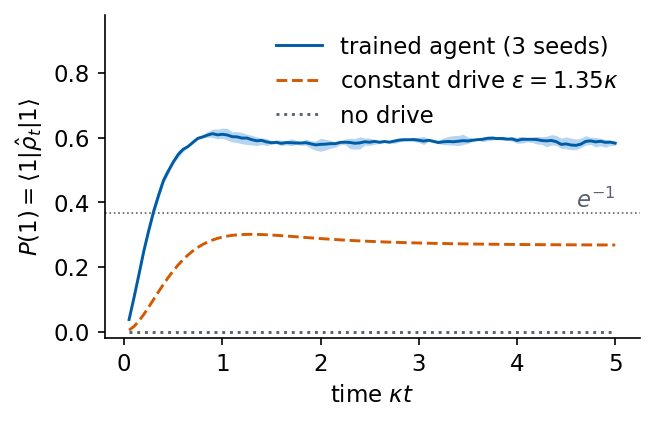

In [21]:
B_EVAL = 2000
eval_keys = [jax.random.split(jax.random.PRNGKey(700 + s_), B_EVAL) for s_ in SEEDS]
rollout_agent_rec = make_rollout(agent_act, U_ACT, record=True)
P1_agent_seeds, avg_seeds, late_seeds, sem_seeds = [], [], [], []
for i in range(len(SEEDS)):
    out = [np.asarray(v) for v in rollout_agent_rec(params_seed[i], eval_keys[i])]
    if i == 0:
        obs_e, acts_e, rews_e, x_e, pops_e = out                 # seed 0 is kept for the figures below
    r = out[2]
    P1_agent_seeds.append(r.mean(0)); avg_seeds.append(r.mean()); late_seeds.append(r[:, T // 2:].mean())
    sem_seeds.append(r.mean(1).std() / np.sqrt(B_EVAL))     # standard error of the episode average
P1_agent_seeds, avg_seeds, late_seeds = np.array(P1_agent_seeds), np.array(avg_seeds), np.array(late_seeds)

# best constant drive: exact density-matrix average, and the same drive simulated with trajectories
P1_const_t, rho_const_end = [np.asarray(v) for v in rho_constant_drive(eps_best, True)]
rollout_const = make_rollout(lambda th, k, obs: jnp.int32(0), drive_unitaries([eps_best]))
rews_c = np.asarray(rollout_const(None, jax.random.split(jax.random.PRNGKey(8), B_EVAL))[2])
tgrid = dt * np.arange(1, T + 1)
const_late = float(P1_const_t[T // 2:].mean())
top_pop = float(pops_e[:, :, -2:].sum(-1).max())
for i in range(len(SEEDS)):
    print(f"trained agent, seed {SEEDS[i]}: episode average P(1) = {avg_seeds[i]:.3f} +- {sem_seeds[i]:.3f}, second half {late_seeds[i]:.3f}")
print(f"best constant drive    : episode average P(1) = {P1_const_best:.3f} (exact), {rews_c.mean():.3f} +- {rews_c.mean(1).std()/np.sqrt(B_EVAL):.3f} (trajectories), second half {const_late:.3f}")
print(f"ratio agent / best constant drive, lowest and highest seed: {avg_seeds.min()/P1_const_best:.2f}, {avg_seeds.max()/P1_const_best:.2f}")
print(f"largest population of the two highest Fock levels in any trajectory (seed 0): {top_pop:.2e}")
NUMBERS.update(dict(P1_agent_seeds=avg_seeds.tolist(), P1_agent_late_seeds=late_seeds.tolist(), P1_agent_sem=float(max(sem_seeds)),
                    P1_const_late=const_late, P1_const_traj=float(rews_c.mean()), top_pop=top_pop,
                    ratio_min=float(avg_seeds.min() / P1_const_best), ratio_max=float(avg_seeds.max() / P1_const_best)))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.fill_between(tgrid, P1_agent_seeds.min(0), P1_agent_seeds.max(0), color=UJSky, alpha=0.5, lw=0)
    ax.plot(tgrid, P1_agent_seeds.mean(0), color=C_AGENT, label=f"trained agent ({len(SEEDS)} seeds)")
    ax.plot(tgrid, P1_const_t, color=C_CONST, ls="--", label=rf"constant drive $\varepsilon={eps_best:g}\kappa$")
    ax.plot(tgrid, np.zeros(T), color=C_NONE, ls=":", label="no drive")
    ax.axhline(np.exp(-1), color=UJGray, lw=0.8, ls=":"); ax.text(4.6, np.exp(-1) + 0.015, r"$e^{-1}$", color=UJGray, fontsize=11)
    ax.set_xlabel(r"time $\kappa t$"); ax.set_ylabel(r"$P(1)=\langle1|\hat\rho_t|1\rangle$")
    ax.set_ylim(-0.02, 0.98); ax.legend(loc="upper right", ncol=1)
    save(fig, "fig_lab053_P1_time"); plt.show()

In the curves above $P(1)=\langle1|\hat\rho_t|1\rangle$ is the average of $|\langle1|\psi_t\rangle|^2$ over the test trajectories, the probability that a photon-number measurement at time $t$ finds one photon. The blue line is the mean of the three agents and the shaded band the range between the lowest and the highest seed. Without a drive the cavity stays empty. The constant drive raises $P(1)$ to about 0.3 within a time of about $1/\kappa$ and then settles, with the average 0.271 over the second half of the episode. The agent fills the cavity faster and then holds the probability of one photon well above $e^{-1}$, with second-half averages between 0.582 and 0.595. The episode averages of the three agents are 0.557 to 0.566 with standard errors of at most 0.003, between 2.16 and 2.19 times the value of the best constant drive. The trajectory simulation of the constant drive gives 0.258 with a standard error of 0.002, the same as the density-matrix value. The two highest Fock levels hold a population of at most $1.06\times10^{-14}$ in any test trajectory of seed 0, so for this agent the cut at 12 levels has no visible effect. The other seeds were not checked in this way.

One test trajectory of the agent of seed 0 shows how the agent works. We pick the trajectory with the median episode average. The upper panel shows the meter readings (grey dots, left axis) and the drive chosen after each reading (blue line, right axis), the lower panel the probability of one photon in this trajectory, which the agent does not see.

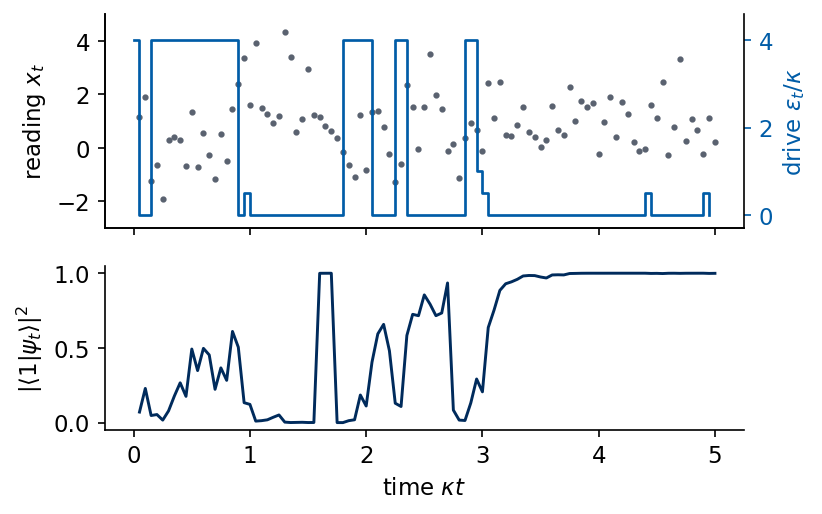

In [22]:
b_ex = int(np.argsort(rews_e.mean(1))[B_EVAL // 2])       # a trajectory with the median episode average
with mpl.rc_context(SLIDE_RC):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5.5, 3.6), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
    ax1.plot(tgrid, x_e[b_ex], ".", color=UJGray, ms=4)
    ax1b = ax1.twinx()
    ax1b.step(tgrid - dt, EPS_ACTIONS[acts_e[b_ex]], where="post", color=C_AGENT, lw=1.3)
    ax1b.set_ylabel(r"drive $\varepsilon_t/\kappa$", color=C_AGENT); ax1b.set_ylim(-0.3, 4.6)
    ax1b.spines["right"].set_visible(True); ax1b.tick_params(axis="y", colors=C_AGENT)
    ax1.set_ylabel(r"reading $x_t$"); ax1.set_ylim(-3, 5)
    ax2.plot(tgrid, rews_e[b_ex], color=UJNavy, lw=1.4)
    ax2.set_ylabel(r"$|\langle1|\psi_t\rangle|^2$"); ax2.set_ylim(-0.05, 1.05)
    ax2.set_xlabel(r"time $\kappa t$")
    save(fig, "fig_lab053_record"); plt.show()

The agent drives hard at the start, when the readings are close to zero, and switches the drive off when the readings suggest one photon. After a loss the readings drift back towards zero, and the agent drives again. The readings are noisy, so the agent acts on an average over several of them, and each decision rests on an estimate of the photon number that can be wrong.

A rule of this kind with two parameters can be written down directly. We scan the rule "strongest drive if the mean of the last $m$ readings is below the threshold $x_{\rm th}$, otherwise no drive" over $m$ and $x_{\rm th}$ and compare its best version with the agent. The scan uses 1000 trajectories per setting, and the best rule is then tested on the same three test sets as the agents.

In [23]:
IMAX = int(np.argmax(EPS_ACTIONS))
def rule_act(theta, key, window):
    """Strongest drive if the weighted mean of the readings is below x_th, otherwise no drive.
    theta = (w, x_th) with the weights w = 1/m on the last m readings."""
    w, x_th = theta
    return jnp.where(jnp.dot(w, window) < x_th, IMAX, 0)
rollout_rule = make_rollout(rule_act, U_ACT)

def weights(m):
    return jnp.zeros(K_OBS).at[-m:].set(1.0 / m)

rule_scan = {}
keys_scan = jax.random.split(jax.random.PRNGKey(11), 1000)
for m in (1, 2, 4, 6, 10):
    for x_th in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
        rule_scan[(m, x_th)] = float(rollout_rule((weights(m), x_th), keys_scan)[2].mean())
(m_best, x_th_best) = max(rule_scan, key=rule_scan.get)
rule_seeds = np.array([float(rollout_rule((weights(m_best), x_th_best), eval_keys[i])[2].mean()) for i in range(len(SEEDS))])
rule_best = float(rule_seeds.mean())
print(f"best threshold rule: m = {m_best}, x_th = {x_th_best}")
print(f"episode average P(1) on the three test sets of the agent: rule {np.round(rule_seeds, 3)}, agent {np.round(avg_seeds, 3)}")
print(f"best constant drive: {P1_const_best:.3f}")
NUMBERS.update(dict(rule_m=m_best, rule_c=x_th_best, P1_rule_seeds=rule_seeds.tolist()))

best threshold rule: m = 4, x_th = 0.4
episode average P(1) on the three test sets of the agent: rule [0.55  0.549 0.55 ], agent [0.562 0.557 0.566]
best constant drive: 0.258


The threshold rule shows that the feedback itself is what beats the constant drive. The best rule on the scanned grid, 5 window lengths times 6 thresholds with the drives $0$ and $4\kappa$ and 1000 trajectories per setting, written down after looking at what the agent does, reaches 0.549 to 0.550 on the three test sets. The three trained networks reach 0.557 to 0.566 on the same sets. The rule and the agents share random keys, but their actions differ, so the two runs are effectively independent and the standard error of their difference is about 0.004. The gain of 0.008 to 0.016 is therefore two to four standard errors. The network finds a rule of this quality from rewards alone, without being told what the readings mean, in a few minutes of training on a CPU. An optimal feedback policy for this model is not known to us, so neither number is a proven optimum.

At the end of the episode the cavity holds a photon-number distribution that no coherent state has. The figure compares the populations $P(n)$ at $t=5/\kappa$ for the agent of seed 0, for the best constant drive, and for the coherent state with $\bar n=1$.

P(n), n = 0..4, agent         : [0.295 0.586 0.113 0.006 0.   ]
P(n), n = 0..4, constant drive: [0.413 0.268 0.159 0.086 0.042]
Mandel Q at the end: agent -0.511, constant drive 0.653, coherent state 0


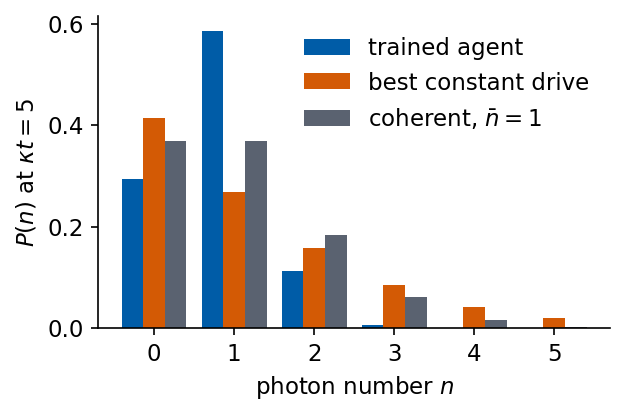

In [24]:
P_end_agent = pops_e[:, -1].mean(0)
P_end_const = np.real(np.diag(rho_const_end))
P_coh = poisson(1.0, N)
nb_agent = float(P_end_agent @ nvec); var_agent = float(P_end_agent @ nvec**2 - nb_agent**2)
Q_agent = var_agent / nb_agent - 1
nb_c = float(P_end_const @ nvec); Q_const = float(P_end_const @ nvec**2 - nb_c**2) / nb_c - 1
print("P(n), n = 0..4, agent         :", np.round(P_end_agent[:5], 3))
print("P(n), n = 0..4, constant drive:", np.round(P_end_const[:5], 3))
print(f"Mandel Q at the end: agent {Q_agent:.3f}, constant drive {Q_const:.3f}, coherent state 0")
NUMBERS.update(dict(Pend_agent=P_end_agent[:4].tolist(), Pend_const=P_end_const[:4].tolist(), Q_agent=Q_agent, Q_const=Q_const))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.7))
    ks = np.arange(6); w = 0.27
    ax.bar(ks - w, P_end_agent[:6], width=w, color=C_AGENT, label="trained agent")
    ax.bar(ks, P_end_const[:6], width=w, color=C_CONST, label="best constant drive")
    ax.bar(ks + w, P_coh[:6], width=w, color=UJGray, label=r"coherent, $\bar n=1$")
    ax.set_xlabel("photon number $n$"); ax.set_ylabel(r"$P(n)$ at $\kappa t=5$")
    ax.set_xticks(ks); ax.legend(loc="upper right")
    save(fig, "fig_lab053_populations"); plt.show()

The agent's cavity has a larger weight on $n=1$, 0.586 against 0.368 for the coherent state, less weight on two or more photons, and the Mandel parameter $Q=-0.511$, a photon number spread below the Poisson value. Feedback from a photon-number measurement has thus produced sub-Poissonian light, which a linear drive alone cannot produce. With the meter on, the constant drive gives a distribution broader than the Poisson distribution, $Q=0.653$. Without feedback the cavity holds a mixture of coherent states with spread amplitudes and phases, and for such a mixture $Q\ge0$, as shown in Section 2.

<hr/>
## 9. Differences from the source setup

The method and the example are due to F. Marquardt, SciPost Phys. Lect. Notes **29** (2021). Our simplified reimplementation keeps its elements, a single decaying cavity mode, a linear drive with discretised amplitudes as the actions, a weak QND measurement of the photon number as the only information, a feedforward network fed with the most recent measurement points, the reward $\langle1|\hat\rho_t|1\rangle$, and policy-gradient training on batches of simulated trajectories. The differences from the original setup are the following.
- The source describes the measurement by a continuous-time stochastic master equation with a measurement rate. We use one discrete reading every $\Delta t$ with Gaussian noise $\sigma$ and the Bayes update, which needs no stochastic calculus. Such discrete readings become a continuous measurement when $\Delta t\to0$ at fixed $\sigma^2\Delta t$ [K. Jacobs and D. A. Steck, Contemp. Phys. **47**, 279 (2006), [doi:10.1080/00107510601101934](https://doi.org/10.1080/00107510601101934)]. We work at finite $\Delta t$.
- The source simulates density matrices. We simulate pure states with random photon losses, and the expected reward is the same.
- The sketch of the setup in the source includes a Kerr term, which the text names as a way to realise the photon-number measurement and as a possible further control. The example reported there, and ours, controls the linear drive only, and the nonlinearity comes from the measurement.
- The values $\Delta t=0.05/\kappa$, $\sigma=1$, $T=100$, the five drive strengths, the network size and the training settings are our choices. The source does not give all of them, so its numbers, for example the probability of about 50% in its figure, are not expected to agree with ours.
- The source plots its training over 400 epochs. We train for 150 epochs, enough for the learning curve to level off in this model, and repeat the training with three random seeds.

<hr/>
## Summary

A cavity mode is a harmonic oscillator, and its Fock state $|1\rangle$ holds exactly one photon. A classical drive produces coherent states with Poisson photon statistics, whose probability of one photon is at most $e^{-1}\approx0.368$. Photon loss is simulated as random jumps $|\psi\rangle\to\hat a|\psi\rangle$ with smooth evolution in between, and a noisy photon-number meter updates the state by Bayes' rule. In the model of this notebook the best constant drive reaches an episode average of $P(1)$ of about a quarter. A policy network that sees the last ten meter readings and chooses among five drive strengths, trained with REINFORCE on simulated trajectories for a few minutes on a CPU, reaches more than twice that value for each of three seeds and holds $P(1)$ above $e^{-1}$, with a sub-Poissonian photon number at the end. The best threshold rule on a scanned grid, written down after the fact, comes within about 0.01 of the trained agents. The policy gradient $\nabla\langle G\rangle=\langle G\,\nabla\ln\pi\rangle$ shares its score-function identity with the fluctuation formula $\partial_\beta\langle E\rangle=-\mathrm{Var}\,E$ of a Boltzmann distribution, an analogy, and it needs no model of the physics, only sampled histories and rewards.

## References

- F. Marquardt, *Machine learning and quantum devices*, SciPost Phys. Lect. Notes **29** (2021), [doi:10.21468/SciPostPhysLectNotes.29](https://doi.org/10.21468/SciPostPhysLectNotes.29), [arXiv:2101.01759](https://arxiv.org/abs/2101.01759)
- L. Mandel, *Sub-Poissonian photon statistics in resonance fluorescence*, Opt. Lett. **4**, 205 (1979), [doi:10.1364/OL.4.000205](https://doi.org/10.1364/OL.4.000205)
- H. M. Wiseman and G. J. Milburn, *Quantum Measurement and Control*, Cambridge University Press (2009), [doi:10.1017/CBO9780511813948](https://doi.org/10.1017/CBO9780511813948)
- K. Jacobs and D. A. Steck, *A straightforward introduction to continuous quantum measurement*, Contemp. Phys. **47**, 279 (2006), [doi:10.1080/00107510601101934](https://doi.org/10.1080/00107510601101934)
- R. J. Williams, *Simple statistical gradient-following algorithms for connectionist reinforcement learning*, Mach. Learn. **8**, 229 (1992), [doi:10.1007/BF00992696](https://doi.org/10.1007/BF00992696)
- D. P. Kingma and J. Ba, *Adam. A method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- R. S. Sutton and A. G. Barto, *Reinforcement Learning. An Introduction*, 2nd ed., MIT Press (2018), [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)

The last cell collects the numbers of this notebook in a JSON file and as LaTeX macros.

In [25]:
NUMBERS["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return to_py(o.tolist())
    return o
with open(f"{OUT}/numbers_lab053.json", "w") as fh:
    json.dump(to_py(NUMBERS), fh, indent=1)

macros = {
    "POneCoherentMax": f"{NUMBERS['P1_coherent_max']:.3f}",
    "Dt": f"{dt:g}", "Sigma": f"{sigma:g}", "EpisodeSteps": f"{T}", "EpisodeTime": f"{T*dt:g}",
    "ErrOneReading": f"{NUMBERS['err1']:.2f}", "ErrFourReadings": f"{NUMBERS['err4']:.2f}",
    "MeterFracOne": f"{NUMBERS['meter_frac_one']:.3f}",
    "EpsBest": f"{eps_best:g}", "POneConstBest": f"{P1_const_best:.3f}",
    "EpsBestOff": f"{eps_best_off:g}", "POneConstBestOff": f"{NUMBERS['P1_const_best_off']:.3f}",
    "NumActions": f"{NA}", "EpsMax": f"{EPS_ACTIONS.max():g}", "InputLength": f"{K_OBS}", "Hidden": f"{HID}",
    "NumParams": f"{n_params}", "Epochs": f"{EPOCHS}", "Batch": f"{BATCH}",
    "TrainMinutes": f"{train_time/60:.1f}", "TrainSeconds": f"{train_time:.0f}",
    "POneUntrained": f"{NUMBERS['curve_first']:.3f}",
    "NumSeeds": f"{len(SEEDS)}",
    "POneAgentMin": f"{avg_seeds.min():.3f}", "POneAgentMax": f"{avg_seeds.max():.3f}", "POneAgentMean": f"{avg_seeds.mean():.3f}",
    "POneAgentSem": f"{max(sem_seeds):.3f}",
    "POneAgentLateMin": f"{late_seeds.min():.3f}", "POneAgentLateMax": f"{late_seeds.max():.3f}",
    "POneConstLate": f"{const_late:.3f}",
    "RatioMin": f"{NUMBERS['ratio_min']:.2f}", "RatioMax": f"{NUMBERS['ratio_max']:.2f}",
    "RuleM": f"{m_best}", "RuleC": f"{x_th_best:g}",
    "POneRuleMin": f"{rule_seeds.min():.3f}", "POneRuleMax": f"{rule_seeds.max():.3f}",
    "PendAgentZero": f"{P_end_agent[0]:.2f}", "PendAgentOne": f"{P_end_agent[1]:.2f}", "PendAgentTwo": f"{P_end_agent[2]:.2f}",
    "PendConstZero": f"{P_end_const[0]:.2f}", "PendConstOne": f"{P_end_const[1]:.2f}", "PendConstTwo": f"{P_end_const[2]:.2f}",
    "MandelQAgent": f"{Q_agent:.2f}", "MandelQConst": f"{Q_const:.2f}",
    "RuntimeMinutes": f"{NUMBERS['runtime_s']/60:.1f}",
}
def thin(val):
    # integers of five or more digits get a thin space between groups of three digits, 20\,000, but 5000
    return f"{int(val):,}".replace(",", "\\,") if val.isdigit() and len(val) >= 5 else val
with open(f"{OUT}/nb_numbers_lab053.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfiftythree{k}}}{{{thin(val)}}}\n")
print(open(f"{OUT}/nb_numbers_lab053.tex").read())
print(f"runtime of the notebook: {NUMBERS['runtime_s']:.0f} s")

\newcommand{\labfiftythreePOneCoherentMax}{0.368}
\newcommand{\labfiftythreeDt}{0.05}
\newcommand{\labfiftythreeSigma}{1}
\newcommand{\labfiftythreeEpisodeSteps}{100}
\newcommand{\labfiftythreeEpisodeTime}{5}
\newcommand{\labfiftythreeErrOneReading}{0.31}
\newcommand{\labfiftythreeErrFourReadings}{0.16}
\newcommand{\labfiftythreeMeterFracOne}{0.369}
\newcommand{\labfiftythreeEpsBest}{1.35}
\newcommand{\labfiftythreePOneConstBest}{0.258}
\newcommand{\labfiftythreeEpsBestOff}{0.7}
\newcommand{\labfiftythreePOneConstBestOff}{0.292}
\newcommand{\labfiftythreeNumActions}{5}
\newcommand{\labfiftythreeEpsMax}{4}
\newcommand{\labfiftythreeInputLength}{10}
\newcommand{\labfiftythreeHidden}{64}
\newcommand{\labfiftythreeNumParams}{5189}
\newcommand{\labfiftythreeEpochs}{150}
\newcommand{\labfiftythreeBatch}{256}
\newcommand{\labfiftythreeTrainMinutes}{2.5}
\newcommand{\labfiftythreeTrainSeconds}{152}
\newcommand{\labfiftythreePOneUntrained}{0.247}
\newcommand{\labfiftythreeNumSeeds}{3}
\newcomma